# Análisis de la Violencia Homicida en América Latina

**Dataset:** [Global Gun Violence & Civilian Firearms — Kaggle](https://www.kaggle.com/datasets/dhananjayk2609/global-gun-violence-and-civilian-firearms)  


## **1. Comprensión de los Datos**

El conjunto de datos seleccionado para este proyecto es Global Gun Violence & Civilian Firearms, obtenido de la plataforma Kaggle. Este conjunto integra información internacional relacionada con la violencia homicida, la tenencia de armas de fuego por parte de civiles y diferentes indicadores socioeconómicos y demográficos.

Su propósito dentro del proyecto es permitir el análisis de la relación entre la disponibilidad de armas de fuego, los niveles de violencia homicida y las condiciones socioeconómicas de los países. En particular, se busca identificar patrones y diferencias entre regiones, así como explorar posibles asociaciones entre la tenencia civil de armas y las tasas de homicidio.

###**Procedencia de la información**

La información fue descargada de Kaggle y se encuentra organizada en cuatro archivos CSV. Es importante señalar que Kaggle funciona como plataforma de distribución: las fuentes estadísticas originales incluyen bases de organismos especializados, entre ellas las del Small Arms Survey, que recopila y sistematiza información internacional sobre armas pequeñas y muertes violentas.

Por ejemplo, su base Global Violent Deaths (GVD) integra información de gobiernos, organismos nacionales e internacionales, organizaciones no gubernamentales y medios de comunicación verificados. La información se presenta por país y año, e incluye desgloses por sexo de las víctimas y mecanismo utilizado para causar la muerte.

Para facilitar la integración de las diferentes fuentes, se utiliza la variable iso3, que corresponde al código internacional de tres letras que identifica a cada país. En los archivos que contienen información temporal, esta variable se complementa con year, permitiendo identificar las observaciones correspondientes a cada país y año.

### **Estructura de los archivos**

| Archivo | Unidad de observación | Contenido principal |
| :--- | :--- | :--- |
| `civilian_firearms_2017.csv` | País (`iso3`) | Estimaciones de *Small Arms Survey* (2017): arsenal civil total, tasa por 100 habitantes, armas registradas y no registradas, región/subregión y método de cómputo. |
| `country_gun_profile.csv` | País (`iso3`) | Perfil integral que combina tenencia de armas (2017) con tasas recientes y promedios decenales (2013–2022) de homicidio total y con arma de fuego, porcentaje de homicidios con arma, región, grupo de ingreso, PIB per cápita, índice de Gini y urbanización. |
| `firearm_homicides_country_year.csv` | País y año (`iso3`, `year`) | Serie anual de homicidios totales, con arma de fuego, tasas por sexo (`male_homicide_rate`, `female_homicide_rate`), violencia de pareja íntima (`ipv`), porcentaje de armas incautadas de origen ilícito y variables socioeconómicas/demográficas. |
| `homicide_long_run_western_europe.csv` | País y año (`iso3`, `year`) | Reconstrucción histórica de tasas de homicidio por cada 100,000 habitantes en Europa Occidental agrupadas por año y siglo. |

###**Variables disponibles**
Las variables se pueden clasificar en cinco grandes grupos:

1. Tenencia civil de armas de fuego

Permiten describir la disponibilidad de armas entre la población civil de cada país.
- civilian_firearms: estimación del número total de armas en posesión de civiles.
- firearms_per_100: estimación de armas por cada 100 habitantes.
- registered_firearms: cantidad estimada de armas registradas.
- unregistered_firearms: cantidad estimada de armas no registradas.
- region y subregion: clasificación geográfica de los países.
2. Violencia homicida y uso de armas de fuego

Contienen información sobre la magnitud de la violencia homicida y la participación de armas de fuego en estos acontecimientos.
- homicide_rate: tasa de homicidios por cada 100,000 habitantes.
- firearm_homicide_rate: tasa de homicidios cometidos con armas de fuego.
- firearm_homicides: número de homicidios cometidos con armas de fuego.
- firearm_share_of_homicides_pct: porcentaje de homicidios en los que se utilizaron armas de fuego.
- male_homicide_rate: tasa de homicidios correspondiente a hombres.
- female_homicide_rate: tasa de homicidios correspondiente a mujeres.
3. Variables socioeconómicas y demográficas

Permiten estudiar las condiciones estructurales de cada país y explorar su posible relación con los niveles de violencia.
- gdp_per_capita_usd: PIB per cápita expresado en dólares estadounidenses.
- gini_index: indicador de desigualdad en la distribución del ingreso.
- unemployment_pct: porcentaje de desempleo.
- urban_population_pct: porcentaje de población urbana.
- military_spending_pct_gdp: gasto militar como porcentaje del PIB.
- secondary_school_enrollment_pct: porcentaje de matriculación en educación secundaria.
4. Variables demográficas y de contexto

Incluyen información para identificar y clasificar las observaciones:
- country: nombre del país.
- iso3: código internacional del país.
- year: año al que corresponde la observación.
- region: región geográfica.
- income_group: clasificación del país según su nivel de ingreso.
5. Variables relacionadas con violencia de pareja y armas incautadas

Incluyen indicadores complementarios para estudiar otras dimensiones de la violencia:
- ipv: indicador relacionado con violencia de pareja íntima.
- ipv_female_victim_rate: tasa de víctimas femeninas de violencia de pareja íntima.
- ipv_male_victim_rate: tasa de víctimas masculinas de violencia de pareja íntima.
- seized_arms_illicit_origin_pct: porcentaje de armas incautadas cuyo origen se considera ilícito.

### **Preguntas de investigación**
La selección de este conjunto de datos permite abordar las siguientes preguntas de investigación:
1. ¿Qué características comparten los países de América Latina y el Caribe que presentan las mayores tasas de homicidio?
2. ¿Existe una asociación entre la tenencia civil de armas de fuego y las tasas de homicidio con armas de fuego a nivel internacional?
3. ¿Qué regiones presentan una mayor proporción de homicidios cometidos con armas de fuego?
4. ¿Cómo se relacionan las condiciones socioeconómicas, como el ingreso, el desempleo y la desigualdad, con los niveles de violencia homicida?

## **2. Exploración y estadística descriptiva**

### 2.1 Conocimiento inicial de los datos

En esta primera etapa exploramos la estructura de las bases de datos, identificando sus dimensiones, variables principales y niveles de observación.

In [ ]:
try:
    import kagglehub
except ImportError:
    !pip install -q kagglehub
try:
    import seaborn
except ImportError:
    !pip install -q seaborn

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy import stats
import kagglehub, pandas as pd

path = kagglehub.dataset_download("dhananjayk2609/global-gun-violence-and-civilian-firearms")
firearm_homicides_country_year = pd.read_csv(f"{path}/firearm_homicides_country_year.csv")
civilian_firearms_2017 = pd.read_csv(f"{path}/civilian_firearms_2017.csv")
country_gun_profile = pd.read_csv(f"{path}/country_gun_profile.csv")
homicide_long_run_western_europe = pd.read_csv(f"{path}/homicide_long_run_western_europe.csv")


cf = civilian_firearms_2017
cgp = country_gun_profile
fh = firearm_homicides_country_year
we = homicide_long_run_western_europe

for nombre, df in [("civilian_firearms_2017", cf), ("country_gun_profile", cgp),
                   ("firearm_homicides_country_year", fh), ("homicide_long_run_western_europe", we)]:
    print(f"{nombre}: {df.shape[0]} filas x {df.shape[1]} columnas")

Using Colab cache for faster access to the 'global-gun-violence-and-civilian-firearms' dataset.
civilian_firearms_2017: 230 filas x 10 columnas
country_gun_profile: 217 filas x 20 columnas
firearm_homicides_country_year: 3120 filas x 24 columnas
homicide_long_run_western_europe: 751 filas x 5 columnas


In [ ]:
# Identificación y clasificación de variables

datasets = {
    '1. civilian_firearms_2017': cf,
    '2. country_gun_profile': cgp,
    '3. firearm_homicides_country_year': fh,
    '4. homicide_long_run_western_europe': we
}

def clasificar_variable(columna, serie):
    if columna == "iso3":
        return "Identificador"
    elif columna == "year":
        return "Temporal"
    elif pd.api.types.is_datetime64_any_dtype(serie):
        return "Temporal"
    elif pd.api.types.is_bool_dtype(serie):
        return "Categórica"
    elif pd.api.types.is_numeric_dtype(serie):
        return "Numérica"
    else:
        return "Categórica"

for nombre, df in datasets.items():
    print(f"\n{nombre}")
    print(f"Total de variables: {df.shape[1]}")

    resumen = pd.DataFrame({
        "Variable": df.columns,
        "Clasificación": [
            clasificar_variable(col, df[col])
            for col in df.columns
        ]
    })

    display(resumen)



civilian_firearms_2017
Total de variables: 10


,Variable,Clasificación
0,location,Categórica
1,iso3,Identificador
2,firearms_per_100_people,Numérica
3,civilian_firearms,Numérica
4,registered_firearms,Numérica
5,unregistered_firearms,Numérica
6,population_2017,Numérica
7,sas_region,Categórica
8,sas_subregion,Categórica
9,computation_method,Categórica



country_gun_profile
Total de variables: 20


,Variable,Clasificación
0,iso3,Identificador
1,country,Categórica
2,region,Categórica
3,income_group,Categórica
4,latitude,Numérica
5,longitude,Numérica
6,firearms_per_100_people,Numérica
7,civilian_firearms,Numérica
8,registered_firearms,Numérica
9,latest_homicide_rate,Numérica



firearm_homicides_country_year
Total de variables: 24


,Variable,Clasificación
0,iso3,Identificador
1,country,Categórica
2,region,Categórica
3,income_group,Categórica
4,year,Temporal
5,homicide_rate,Numérica
6,homicides,Numérica
7,homicides_total_est,Numérica
8,firearm_homicide_rate,Numérica
9,firearm_homicides,Numérica



homicide_long_run_western_europe
Total de variables: 5


,Variable,Clasificación
0,country,Categórica
1,iso3,Identificador
2,year,Temporal
3,century,Numérica
4,homicide_rate,Numérica


In [ ]:
#Dimensiones y faltantes totales de cada base

datasets = {
    '1. civilian_firearms_2017': cf,
    '2. country_gun_profile': cgp,
    '3. firearm_homicides_country_year': fh,
    '4. homicide_long_run_western_europe': we
}

print("=== DIMENSIONES Y VALORES FALTANTES POR DATASET ===")
for nombre, df in datasets.items():
    total_celdas = df.shape[0] * df.shape[1]
    nulos = df.isnull().sum().sum()
    print(f"{nombre}: {df.shape[0]} filas x {df.shape[1]} columnas | Nulos totales: {nulos} ({nulos/total_celdas*100:.1f}%)")


=== DIMENSIONES Y VALORES FALTANTES POR DATASET ===
1. civilian_firearms_2017: 230 filas x 10 columnas | Nulos totales: 188 (8.2%)
2. country_gun_profile: 217 filas x 20 columnas | Nulos totales: 1117 (25.7%)
3. firearm_homicides_country_year: 3120 filas x 24 columnas | Nulos totales: 19261 (25.7%)
4. homicide_long_run_western_europe: 751 filas x 5 columnas | Nulos totales: 31 (0.8%)


In [ ]:
# Identificación de valores faltantes por variable

datasets = {
    '1. civilian_firearms_2017': cf,
    '2. country_gun_profile': cgp,
    '3. firearm_homicides_country_year': fh,
    '4. homicide_long_run_western_europe': we
}
for nombre, df in datasets.items():

    print(f"\n=== {nombre} ===")

    faltantes = pd.DataFrame({
        "Valores faltantes": df.isnull().sum(),
        "Porcentaje (%)": (df.isnull().mean() * 100).round(2)
    })

    # Mostrar únicamente variables con faltantes
    faltantes = faltantes[
        faltantes["Valores faltantes"] > 0
    ].sort_values("Valores faltantes", ascending=False)

    display(faltantes)



=== 1. civilian_firearms_2017 ===


,Valores faltantes,Porcentaje (%)
registered_firearms,94,40.87
unregistered_firearms,94,40.87



=== 2. country_gun_profile ===


,Valores faltantes,Porcentaje (%)
gini_index_2017,150,69.12
avg_2013_2022_firearm_share_of_homicides_pct,125,57.60
avg_2013_2022_firearm_homicide_rate,121,55.76
latest_firearm_homicide_rate,118,54.38
latest_firearm_homicide_rate_year,118,54.38
urban_population_pct_2017,89,41.01
population_2017,89,41.01
gdp_per_capita_usd_2017,89,41.01
registered_firearms,88,40.55
avg_2013_2022_homicide_rate,54,24.88



=== 3. firearm_homicides_country_year ===


,Valores faltantes,Porcentaje (%)
seized_arms_illicit_origin_pct,3026,96.99
ipv_male_victim_rate,2372,76.03
ipv_female_victim_rate,2345,75.16
firearm_share_of_homicides_pct,2094,67.12
firearm_homicides,2067,66.25
firearm_homicide_rate,2067,66.25
gini_index,1702,54.55
male_homicide_rate,912,29.23
female_homicide_rate,909,29.13
secondary_school_enrollment_pct,710,22.76



=== 4. homicide_long_run_western_europe ===


,Valores faltantes,Porcentaje (%)
iso3,31,4.13


In [ ]:
#Valores faltantes de la tasa de homicidios con arma de fuego por año en América Latina y el Caribe
latam = fh[fh["region"] == "Latin America & Caribbean"]

faltantes = latam.groupby("year")["firearm_homicide_rate"].apply(
    lambda x: x.isna().sum()
)

for i in range(0, len(faltantes), 5):
    grupo = faltantes.iloc[i:i+5]
    print("  |  ".join(
        f"{int(anio)}: {n} faltantes"
        for anio, n in grupo.items()
    ))


2000: 32 faltantes  |  2001: 36 faltantes  |  2002: 36 faltantes  |  2003: 36 faltantes  |  2004: 34 faltantes
2005: 30 faltantes  |  2006: 27 faltantes  |  2007: 26 faltantes  |  2008: 25 faltantes  |  2009: 24 faltantes
2010: 20 faltantes  |  2011: 18 faltantes  |  2012: 16 faltantes  |  2013: 19 faltantes  |  2014: 14 faltantes
2015: 8 faltantes  |  2016: 8 faltantes  |  2017: 5 faltantes  |  2018: 5 faltantes  |  2019: 6 faltantes
2020: 5 faltantes  |  2021: 5 faltantes  |  2022: 5 faltantes  |  2023: 2 faltantes  |  2024: 1 faltantes


In [ ]:
# Identificación de países y territorios por base

bases = {
    "Armas civiles (2017)": cf,
    "Perfil de armas por país": cgp,
    "Homicidios por país y año": fh,
    "Homicidios históricos de Europa": we
}

for nombre, df in bases.items():
    cantidad = df["iso3"].nunique()
    print(f"{nombre}: {cantidad} países/territorios")

# Países de América Latina y el Caribe
latam = fh[fh["region"] == "Latin America & Caribbean"]

print(
    f"\nAmérica Latina y el Caribe: "
    f"{latam['iso3'].nunique()} países/territorios"
)


Armas civiles (2017): 230 países/territorios
Perfil de armas por país: 217 países/territorios
Homicidios por país y año: 187 países/territorios
Homicidios históricos de Europa: 9 países/territorios

América Latina y el Caribe: 41 países/territorios


In [ ]:
#Cobertura de datos de homicidios con arma de fuego por región geográfica.
cobertura_regional = fh.groupby('region')['firearm_homicide_rate'].apply(
    lambda s: pd.Series({'obs_totales': len(s), 'obs_validas': s.notnull().sum(), 'cobertura_pct': round(s.notnull().mean()*100, 1)})
).unstack()
print("\nCobertura de tasa de homicidio con arma por región (2000-2024):")
cobertura_regional


Cobertura de tasa de homicidio con arma por región (2000-2024):


,obs_totales,obs_validas,cobertura_pct
region,,,
East Asia & Pacific,448.0,91.0,20.3
Europe & Central Asia,1052.0,415.0,39.4
Latin America & Caribbean,816.0,373.0,45.7
"Middle East, North Africa, Afghanistan & Pakistan",324.0,72.0,22.2
North America,70.0,52.0,74.3
South Asia,109.0,24.0,22.0
Sub-Saharan Africa,301.0,26.0,8.6


#Interpretación
#"Cobertura de datos de homicidios con arma de fuego por región geográfica".
La disponibilidad de datos no es uniforme entre regiones. En América Latina y el Caribe, únicamente el 45.7% de los registros cuenta con información sobre homicidios con arma de fuego. Esto representa una limitación importante, ya que los valores faltantes pueden afectar las comparaciones y deben considerarse antes de extraer conclusiones.

In [ ]:
#Cobertura de datos de homicidios con arma de fuego por país
cobertura_pais = fh.groupby('country')['firearm_homicide_rate'].apply(
    lambda s: pd.Series({'obs_totales': len(s), 'obs_validas': s.notnull().sum(), 'cobertura_pct': round(s.notnull().mean()*100, 1)})
).unstack().sort_values(by='cobertura_pct', ascending=False)
print("\nCobertura de tasa de homicidio con arma por país (2000-2024):")
cobertura_pais


Cobertura de tasa de homicidio con arma por país (2000-2024):


,obs_totales,obs_validas,cobertura_pct
country,,,
Bolivia,9.0,9.0,100.0
Peru,11.0,11.0,100.0
Sri Lanka,15.0,13.0,86.7
United States,22.0,19.0,86.4
Switzerland,18.0,15.0,83.3
...,...,...,...
"Venezuela, RB",21.0,0.0,0.0
Virgin Islands (U.S.),13.0,0.0,0.0
"Yemen, Rep.",8.0,0.0,0.0


#Interpretación
#"Cobertura de datos de homicidios con arma de fuego por región país".
Observamos diferencias importantes en la disponibilidad de información entre países. Por ejemplo, Bolivia y Perú presentan una cobertura del 100% de sus registros disponibles, mientras que Venezuela no cuenta con datos válidos de este indicador.

Esto evidencia que la información no es igualmente completa en todos los países, lo cual debemos considerar al realizar comparaciones internacionales.

In [ ]:
#Porcentaje de armas civiles que están registradas
cf['pct_registered'] = np.where(
    cf['registered_firearms'].notnull() & (cf['civilian_firearms'] > 0),
    (cf['registered_firearms'] / cf['civilian_firearms']) * 100,
    np.nan
)
cf

,location,iso3,firearms_per_100_people,civilian_firearms,registered_firearms,unregistered_firearms,population_2017,sas_region,sas_subregion,computation_method,pct_registered
0,United States,USA,120.50,393347000,1073743.0,392273257.0,326474000,Americas,North America,survey and expert estimate,0.272976
1,Falkland Islands,FLK,62.10,2000,1705.0,295.0,3000,Americas,South America,expert estimate,85.250000
2,Yemen,YEM,52.80,14859000,NaN,NaN,28120000,Asia,Western Asia,expert estimate,NaN
3,New Caledonia,NCL,42.50,115000,55000.0,60000.0,270000,Oceania,Melanesia,expert estimate,47.826087
4,Serbia,SRB,39.10,2719000,1186086.0,1532914.0,6946000,Europe,Southern Europe,expert estimate,43.622140
...,...,...,...,...,...,...,...,...,...,...,...
225,Taiwan,TWN,0.04,10000,5000.0,5000.0,23405000,Asia,East Asia,expert estimate,50.000000
226,Indonesia,IDN,0.03,82000,41102.0,40898.0,263510000,Asia,South-East Asia,expert estimate,50.124390
227,Nauru,NRU,0.00,0,NaN,NaN,10000,Oceania,Melanesia,expert estimate,NaN
228,Christmas Island,CXR,0.00,0,NaN,NaN,2000,Asia,South-East Asia,expert estimate,NaN


In [ ]:
cgp_limpio = cgp.merge(cf[['iso3', 'population_2017']], on='iso3', how='left', suffixes=('', '_sas'))
cgp_limpio['population_2017_filled'] = cgp_limpio['population_2017'].fillna(cgp_limpio['population_2017_sas'])
print(f"Nulos en population_2017 antes: {cgp['population_2017'].isnull().sum()} -> después del merge SAS: {cgp_limpio['population_2017_filled'].isnull().sum()}")


Nulos en population_2017 antes: 89 -> después del merge SAS: 1


#Interpretación
#"Porcentaje de armas civiles que están registradas"
Observamos diferencias importantes entre países en el porcentaje de armas civiles registradas, lo que nos indica que la proporción de armas registradas oficialmente no es la misma en todos los territorios.

Por otra parte, al complementar los datos de población de 2017, logramos reducir los valores faltantes de 89 a solamente uno. Esto nos permite contar con información más completa y realizar un análisis más confiable.

### 2.2 Estadística descriptiva

En esta etapa calculamos medidas de tendencia central, dispersión y posición para comprender el comportamiento de las principales variables del conjunto de datos.

In [ ]:
# Estadística descriptiva de las variables principales

variables_clave = [
    'firearms_per_100_people',
    'avg_2013_2022_homicide_rate',
    'avg_2013_2022_firearm_homicide_rate',
    'avg_2013_2022_firearm_share_of_homicides_pct',
    'gdp_per_capita_usd_2017',
    'gini_index_2017'
]

# Cálculos originales
resumen_desc = cgp[variables_clave].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
).T

resumen_desc['IQR'] = resumen_desc['75%'] - resumen_desc['25%']
resumen_desc['CV'] = resumen_desc['std'] / resumen_desc['mean']
resumen_desc['Asimetria'] = cgp[variables_clave].skew()

columnas_orden = [
    'count', 'mean', '50%', 'std', 'IQR',
    'CV', 'Asimetria', 'min', '25%', '75%', 'max'
]

resumen_desc = resumen_desc[columnas_orden].rename(
    columns={
        'count': 'n',
        'mean': 'Media',
        '50%': 'Mediana',
        'std': 'DE'
    }
)

# Traducir únicamente los nombres mostrados
tabla = resumen_desc.rename(
    index={
        'firearms_per_100_people': 'Armas por cada 100 habitantes',
        'avg_2013_2022_homicide_rate': 'Tasa de homicidios',
        'avg_2013_2022_firearm_homicide_rate': 'Tasa de homicidios con arma',
        'avg_2013_2022_firearm_share_of_homicides_pct': 'Homicidios con arma (%)',
        'gdp_per_capita_usd_2017': 'PIB por habitante (USD)',
        'gini_index_2017': 'Índice de Gini'
    },
    columns={
        'n': 'Observaciones',
        'DE': 'Desv. estándar',
        'IQR': 'Rango intercuartílico',
        'CV': 'Coef. de variación',
        'Asimetria': 'Asimetría',
        'min': 'Mínimo',
        'max': 'Máximo'
    }
)

# Tabla 1: Tendencia central y posición
print("MEDIDAS DE TENDENCIA CENTRAL Y POSICIÓN")

columnas_1 = [
    'Observaciones', 'Media', 'Mediana',
    'Mínimo', '25%', '75%', 'Máximo'
]

display(
    tabla[columnas_1].style
    .format("{:,.2f}")
    .format("{:,.0f}", subset=['Observaciones'])
)

# Tabla 2: Dispersión y forma
print("MEDIDAS DE DISPERSIÓN Y ASIMETRÍA")

columnas_2 = [
    'Desv. estándar', 'Rango intercuartílico',
    'Coef. de variación', 'Asimetría'
]

display(
    tabla[columnas_2].style
    .format("{:,.2f}")
)


MEDIDAS DE TENDENCIA CENTRAL Y POSICIÓN


,Observaciones,Media,Mediana,Mínimo,25%,75%,Máximo
Armas por cada 100 habitantes,215,9.70,5.40,0.00,2.05,13.65,120.50
Tasa de homicidios,163,7.13,2.72,0.00,1.06,8.35,50.01
Tasa de homicidios con arma,96,4.55,0.38,0.00,0.12,3.81,38.36
Homicidios con arma (%),92,31.77,26.76,0.00,8.91,51.46,89.89
PIB por habitante (USD),128,"21,325.69","10,369.71",525.47,"4,320.65","28,547.92","170,547.09"
Índice de Gini,67,35.19,34.40,23.20,30.40,38.60,53.30


MEDIDAS DE DISPERSIÓN Y ASIMETRÍA


,Desv. estándar,Rango intercuartílico,Coef. de variación,Asimetría
Armas por cada 100 habitantes,12.33,11.60,1.27,4.13
Tasa de homicidios,10.32,7.29,1.45,2.32
Tasa de homicidios con arma,8.82,3.69,1.94,2.48
Homicidios con arma (%),25.76,42.55,0.81,0.52
PIB por habitante (USD),"26,832.62","24,227.27",1.26,2.48
Índice de Gini,7.09,8.20,0.20,0.64


#Interpretación
En general, observamos diferencias importantes entre países, tanto en la tenencia de armas y las tasas de homicidios como en los indicadores económicos. Las medias superiores a las medianas y la elevada dispersión nos indican que algunos países presentan valores considerablemente altos, lo que influye en los promedios y refleja una distribución desigual de estas variables.

In [ ]:
# Estadística descriptiva de la tenencia civil de armas (2017)

resumen = cf[
    ['firearms_per_100_people', 'civilian_firearms', 'pct_registered']
].describe(
    percentiles=[0.25, 0.5, 0.75, 0.90]
).round(2)

# Traducir los nombres de las medidas y variables
resumen = resumen.rename(
    index={
        'count': 'Observaciones válidas',
        'mean': 'Media (promedio)',
        'std': 'Desviación estándar',
        'min': 'Mínimo',
        '25%': '25%',
        '50%': '50% (mediana)',
        '75%': '75%',
        '90%': '90%',
        'max': 'Máximo'
    },
    columns={
        'firearms_per_100_people': 'Armas por cada 100 habitantes',
        'civilian_firearms': 'Total de armas civiles',
        'pct_registered': 'Porcentaje de armas registradas'
    }
)

print("Estadística descriptiva de la tenencia civil de armas (2017)")
display(resumen.style.format("{:,.2f}"))


Estadística descriptiva de la tenencia civil de armas (2017)


,Armas por cada 100 habitantes,Total de armas civiles,Porcentaje de armas registradas
Observaciones válidas,230.00,230.00,136.00
Media (promedio),9.87,"3,734,466.94",37.72
Desviación estándar,12.51,"26,720,932.19",23.83
Mínimo,0.00,0.00,0.02
25%,2.10,"31,500.00",18.85
50% (mediana),5.90,"240,000.00",34.87
75%,13.68,"1,042,500.00",52.99
90%,22.38,"3,964,900.00",72.06
Máximo,120.50,"393,347,000.00",99.01


#Interpretación
En la información de 2017, la tenencia media es de 9.87 armas por cada 100 habitantes, frente a una mediana de 5.90. La diferencia entre ambas medidas sugiere que la distribución de armas civiles es desigual y que algunos países presentan valores elevados respecto al conjunto analizado.

In [ ]:
# Promedios de tenencia de armas y homicidios por nivel de ingreso

# Orden de los grupos de ingreso
orden_ingreso = [
    'Low income',
    'Lower middle income',
    'Upper middle income',
    'High income'
]

# Calcular los promedios por nivel de ingreso
resumen_ingreso = (
    cgp_limpio.groupby('income_group')[[
        'firearms_per_100_people',
        'avg_2013_2022_homicide_rate',
        'avg_2013_2022_firearm_homicide_rate',
        'avg_2013_2022_firearm_share_of_homicides_pct'
    ]]
    .mean()
    .reindex(orden_ingreso)
    .round(2)
)

# Traducir grupos de ingreso y variables
resumen_ingreso = resumen_ingreso.rename(
    index={
        'Low income': 'Ingreso bajo',
        'Lower middle income': 'Ingreso medio-bajo',
        'Upper middle income': 'Ingreso medio-alto',
        'High income': 'Ingreso alto'
    },
    columns={
        'firearms_per_100_people': 'Armas por cada 100 habitantes',
        'avg_2013_2022_homicide_rate': 'Tasa de homicidios',
        'avg_2013_2022_firearm_homicide_rate': 'Tasa de homicidios con arma de fuego',
        'avg_2013_2022_firearm_share_of_homicides_pct': 'Homicidios con arma de fuego (%)'
    }
)

print("Promedios por nivel de ingreso")
display(resumen_ingreso.style.format("{:,.2f}"))


Promedios por nivel de ingreso


,Armas por cada 100 habitantes,Tasa de homicidios,Tasa de homicidios con arma de fuego,Homicidios con arma de fuego (%)
income_group,,,,
Ingreso bajo,5.16,5.11,0.52,5.17
Ingreso medio-bajo,4.51,7.57,4.29,20.25
Ingreso medio-alto,9.25,9.91,6.63,38.19
Ingreso alto,14.26,5.14,3.08,29.79


#Interpretación

Observamos que los países de ingresos altos presentan la mayor tenencia promedio de armas, con 14.26 por cada 100 habitantes. Sin embargo, los países de ingreso medio-alto registran las tasas más elevadas de homicidios, tanto generales como con arma de fuego. Esto nos muestra que una mayor tenencia de armas no necesariamente coincide con mayores tasas de homicidios.

2.2.1 Estadística descriptivas por región geográfica




In [ ]:
fh.groupby("region")["homicide_rate"].describe()
# Nombres de las regiones en español
regiones_es = {
    "East Asia & Pacific": "Asia Oriental y el Pacífico",
    "Europe & Central Asia": "Europa y Asia Central",
    "Latin America & Caribbean": "América Latina y el Caribe",
    "Middle East, North Africa, Afghanistan & Pakistan":
        "Oriente Medio, Norte de África, Afganistán y Pakistán",
    "North America": "América del Norte",
    "South Asia": "Asia del Sur",
    "Sub-Saharan Africa": "África subsahariana"
}

# Nombres de las medidas estadísticas
columnas_es = {
    "count": "Observaciones",
    "mean": "Media",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "25%",
    "50%": "50% (mediana)",
    "75%": "75%",
    "max": "Máximo"
}

# Las seis variables originales
variables = {
    "homicide_rate": "Tasa general de homicidios",
    "firearm_homicide_rate": "Tasa de homicidios con arma de fuego",
    "male_homicide_rate": "Tasa de homicidios masculinos",
    "female_homicide_rate": "Tasa de homicidios femeninos",
    "secondary_school_enrollment_pct": "Escolarización secundaria (%)",
    "unemployment_pct": "Desempleo (%)"
}

# Estadística descriptiva por región
for variable, titulo in variables.items():

    resumen = (
        fh.groupby("region")[variable]
          .describe()
          .rename(index=regiones_es, columns=columnas_es)
    )

    resumen.index.name = "Región geográfica"

    print(f"\n{titulo} por región geográfica")

    display(
        resumen.style
        .format("{:,.2f}")
        .format("{:,.0f}", subset=["Observaciones"])
    )


Tasa general de homicidios por región geográfica


,Observaciones,Media,Desviación estándar,Mínimo,25%,50% (mediana),75%,Máximo
Región geográfica,,,,,,,,
Asia Oriental y el Pacífico,445,2.84,3.52,0.00,0.65,1.35,3.79,28.66
Europa y Asia Central,"1,048",2.61,3.58,0.00,0.88,1.39,2.63,30.32
América Latina y el Caribe,811,20.95,16.37,0.00,8.31,16.01,28.66,107.64
"Oriente Medio, Norte de África, Afganistán y Pakistán",323,2.11,1.98,0.00,0.87,1.54,2.53,15.86
América del Norte,69,4.66,3.22,0.00,1.81,4.73,6.30,13.90
Asia del Sur,108,2.87,1.36,0.61,2.25,2.71,3.34,10.04
África subsahariana,300,9.42,9.71,1.00,3.15,5.65,11.41,46.14



Tasa de homicidios con arma de fuego por región geográfica


,Observaciones,Media,Desviación estándar,Mínimo,25%,50% (mediana),75%,Máximo
Región geográfica,,,,,,,,
Asia Oriental y el Pacífico,91,0.48,0.95,0.00,0.01,0.14,0.23,4.21
Europa y Asia Central,415,0.37,0.51,0.00,0.10,0.21,0.42,3.44
América Latina y el Caribe,373,14.66,14.48,0.00,3.68,8.56,22.65,89.53
"Oriente Medio, Norte de África, Afganistán y Pakistán",72,0.28,0.36,0.00,0.02,0.14,0.45,2.02
América del Norte,52,2.76,2.41,0.00,0.65,2.79,3.58,10.98
Asia del Sur,24,0.56,1.17,0.00,0.05,0.24,0.33,5.04
África subsahariana,26,1.17,1.68,0.00,0.09,0.43,1.34,6.05



Tasa de homicidios masculinos por región geográfica


,Observaciones,Media,Desviación estándar,Mínimo,25%,50% (mediana),75%,Máximo
Región geográfica,,,,,,,,
Asia Oriental y el Pacífico,234,3.85,6.22,0.00,0.47,1.27,4.51,50.10
Europa y Asia Central,919,3.43,5.09,0.00,1.03,1.79,3.56,49.30
América Latina y el Caribe,655,38.37,31.05,0.00,14.60,28.68,53.00,206.46
"Oriente Medio, Norte de África, Afganistán y Pakistán",195,2.38,2.97,0.00,0.77,1.83,2.86,27.54
América del Norte,63,7.97,6.33,0.00,2.67,7.35,10.13,28.36
Asia del Sur,42,4.38,2.35,1.24,3.39,4.23,4.90,16.37
África subsahariana,100,16.23,18.47,0.00,4.60,9.71,18.07,73.37


... (2 outputs left out)


Escolarización secundaria (%) por región geográfica


,Observaciones,Media,Desviación estándar,Mínimo,25%,50% (mediana),75%,Máximo
Región geográfica,,,,,,,,
Asia Oriental y el Pacífico,269,88.98,22.79,18.13,78.01,92.04,101.05,159.11
Europa y Asia Central,915,102.80,14.03,47.66,94.18,101.38,109.49,157.65
América Latina y el Caribe,613,89.35,18.31,30.98,76.64,90.61,102.62,138.90
"Oriente Medio, Norte de África, Afganistán y Pakistán",256,81.20,22.38,19.84,68.68,89.56,98.36,114.45
América del Norte,44,98.33,9.97,74.40,87.94,100.16,105.11,111.97
Asia del Sur,94,64.08,17.04,30.52,49.32,63.04,75.62,95.91
África subsahariana,219,59.96,26.05,6.67,37.99,60.50,81.06,112.31



Desempleo (%) por región geográfica


,Observaciones,Media,Desviación estándar,Mínimo,25%,50% (mediana),75%,Máximo
Región geográfica,,,,,,,,
Asia Oriental y el Pacífico,405,4.13,2.45,0.41,2.68,3.82,5.18,15.32
Europa y Asia Central,978,9.29,6.00,0.79,5.11,7.42,11.47,37.16
América Latina y el Caribe,665,8.47,4.51,1.58,5.16,7.61,10.88,25.22
"Oriente Medio, Norte de África, Afganistán y Pakistán",324,7.93,5.97,0.10,2.95,7.81,11.57,27.46
América del Norte,46,6.41,1.62,3.64,5.28,6.46,7.50,9.66
Asia del Sur,109,6.37,2.97,1.66,4.01,5.85,8.30,13.04
África subsahariana,283,10.27,8.45,0.32,3.42,6.43,16.23,34.15


#Interpretación

Claro, lo reformulo sin esa expresión: en América Latina y el Caribe hay tasas de homicidios mucho más altas que en otras regiones, tanto en general como con arma de fuego, y siempre con una gran diferencia entre hombres y mujeres, con cifras mucho más altas en hombres.

### 2.3 Análisis de correlaciones

En esta etapa analizamos las relaciones lineales entre las principales variables mediante **matrices de correlación de Pearson**

In [ ]:
cgp.head()

,iso3,country,region,income_group,latitude,longitude,firearms_per_100_people,civilian_firearms,registered_firearms,latest_homicide_rate,latest_homicide_rate_year,latest_firearm_homicide_rate,latest_firearm_homicide_rate_year,avg_2013_2022_homicide_rate,avg_2013_2022_firearm_homicide_rate,avg_2013_2022_firearm_share_of_homicides_pct,population_2017,gdp_per_capita_usd_2017,gini_index_2017,urban_population_pct_2017
0,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,34.5228,69.17610,12.5,4270000.0,NaN,4.032,2021.0,NaN,NaN,6.847,NaN,NaN,35688935.0,525.47,NaN,24.84
1,ALB,Albania,Europe & Central Asia,Upper middle income,41.3317,19.81720,12.0,350000.0,65747.0,1.755,2024.0,0.889,2023.0,2.649,1.763,67.863,2648285.0,5006.36,33.1,55.98
2,DZA,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,36.7397,3.05097,2.1,877000.0,200000.0,1.161,2023.0,0.108,2023.0,1.399,0.124,8.953,41689299.0,4554.67,NaN,71.32
3,ASM,American Samoa,East Asia & Pacific,High income,-14.2846,-170.69100,0.7,400.0,250.0,0.000,2019.0,NaN,NaN,8.262,NaN,NaN,51586.0,11863.68,NaN,83.89
4,AND,Andorra,Europe & Central Asia,High income,42.5075,1.52180,14.1,10000.0,7599.0,2.585,2020.0,0.000,2015.0,0.646,0.000,NaN,NaN,NaN,NaN,NaN


In [ ]:
cgp.drop(columns=["iso3","country","region","income_group"]).corr()

,latitude,longitude,firearms_per_100_people,civilian_firearms,registered_firearms,latest_homicide_rate,latest_homicide_rate_year,latest_firearm_homicide_rate,latest_firearm_homicide_rate_year,avg_2013_2022_homicide_rate,avg_2013_2022_firearm_homicide_rate,avg_2013_2022_firearm_share_of_homicides_pct,population_2017,gdp_per_capita_usd_2017,gini_index_2017,urban_population_pct_2017
latitude,1.000000,-0.008474,0.274719,0.087199,0.062210,-0.224592,0.257466,-0.241982,-0.170521,-0.260440,-0.243231,-0.284610,0.055285,0.276127,-0.719774,0.124004
longitude,-0.008474,1.000000,-0.145859,-0.072293,0.081187,-0.400252,-0.176991,-0.520359,-0.287174,-0.494882,-0.566704,-0.696488,0.191743,0.056131,-0.543289,0.005556
firearms_per_100_people,0.274719,-0.145859,1.000000,0.624936,0.144910,-0.093188,0.150703,-0.127475,0.158925,-0.064544,-0.094266,0.172281,0.023890,0.312435,-0.026186,0.217876
civilian_firearms,0.087199,-0.072293,0.624936,1.000000,0.204657,-0.023215,0.068815,-0.019949,0.007944,-0.017459,-0.015493,0.131373,0.358217,0.101767,0.129535,0.040635
registered_firearms,0.062210,0.081187,0.144910,0.204657,1.000000,-0.027117,0.094983,-0.111576,-0.238840,0.018491,-0.093040,-0.110982,0.476492,0.019341,0.152273,0.066479
latest_homicide_rate,-0.224592,-0.400252,-0.093188,-0.023215,-0.027117,1.000000,0.032694,0.959893,0.214041,0.810184,0.800796,0.615021,-0.068710,-0.183317,0.640474,-0.224902
latest_homicide_rate_year,0.257466,-0.176991,0.150703,0.068815,0.094983,0.032694,1.000000,0.125847,0.585387,0.126125,0.105182,0.156230,-0.094365,0.140745,0.059021,0.228012
latest_firearm_homicide_rate,-0.241982,-0.520359,-0.127475,-0.019949,-0.111576,0.959893,0.125847,1.000000,0.196688,0.768157,0.795240,0.649283,-0.071391,-0.142779,0.586008,-0.186459
latest_firearm_homicide_rate_year,-0.170521,-0.287174,0.158925,0.007944,-0.238840,0.214041,0.585387,0.196688,1.000000,0.197270,0.176371,0.252450,-0.351744,-0.198015,0.185236,0.085007
avg_2013_2022_homicide_rate,-0.260440,-0.494882,-0.064544,-0.017459,0.018491,0.810184,0.126125,0.768157,0.197270,1.000000,0.960595,0.661514,-0.064133,-0.230769,0.540327,-0.146527


#Interpretación
En general, observamos que los homicidios están fuertemente relacionados con aquellos cometidos con arma de fuego. También encontramos una asociación positiva entre la desigualdad económica y las tasas de homicidios. Sin embargo, la tenencia de armas por habitante presenta una relación lineal muy débil con estas tasas, lo que sugiere que debemos considerar otros factores para comprender las diferencias entre países.

In [ ]:
fh.drop(columns=["iso3","country","region","income_group"]).corr()

,year,homicide_rate,homicides,homicides_total_est,firearm_homicide_rate,firearm_homicides,firearm_share_of_homicides_pct,female_homicide_rate,male_homicide_rate,ipv_female_victim_rate,ipv_male_victim_rate,seized_arms_illicit_origin_pct,population,gdp_per_capita_usd,gini_index,unemployment_pct,urban_population_pct,male_15_64_share_pct,military_spending_pct_gdp,secondary_school_enrollment_pct
year,1.000000,-0.033775,-0.000911,-0.001069,0.000226,0.021455,0.013528,-0.082915,-0.044825,0.041280,0.008434,0.124952,0.014275,0.173325,-0.139356,-0.062004,0.108893,0.107558,-0.031311,0.284306
homicide_rate,-0.033775,1.000000,0.284413,0.284640,0.969736,0.330536,0.605597,0.837510,0.997759,0.291169,0.191539,-0.049398,-0.052469,-0.218198,0.599932,0.127809,-0.089469,-0.152426,-0.157635,-0.171254
homicides,-0.000911,0.284413,1.000000,0.999993,0.192010,0.820196,0.172316,0.287426,0.287977,-0.062244,0.002814,-0.174836,0.581240,-0.132747,0.391925,0.008653,-0.013374,-0.042771,0.038531,-0.129988
homicides_total_est,-0.001069,0.284640,0.999993,1.000000,0.192423,0.819157,0.171808,0.287245,0.288183,-0.062668,0.002299,-0.174746,0.580625,-0.133028,0.392146,0.008873,-0.013454,-0.042964,0.038224,-0.130221
firearm_homicide_rate,0.000226,0.969736,0.192010,0.192423,1.000000,0.330031,0.668337,0.815894,0.976173,0.180397,0.123773,0.092932,-0.051383,-0.221100,0.520506,-0.047525,-0.162795,-0.103106,-0.119309,-0.330577
firearm_homicides,0.021455,0.330536,0.820196,0.819157,0.330031,1.000000,0.330052,0.269412,0.329836,-0.092634,-0.051066,-0.065153,0.366313,-0.045794,0.463808,-0.112035,0.090472,-0.076578,0.130442,-0.111648
firearm_share_of_homicides_pct,0.013528,0.605597,0.172316,0.171808,0.668337,0.330052,1.000000,0.447541,0.617303,0.126090,0.127434,0.138997,-0.025994,-0.151664,0.680402,0.148674,-0.028834,-0.048942,-0.156616,-0.258514
female_homicide_rate,-0.082915,0.837510,0.287426,0.287245,0.815894,0.269412,0.447541,1.000000,0.805642,0.452223,0.256722,-0.056389,0.031186,-0.300798,0.485940,0.107452,-0.244670,-0.171561,-0.129241,-0.288807
male_homicide_rate,-0.044825,0.997759,0.287977,0.288183,0.976173,0.329836,0.617303,0.805642,1.000000,0.271728,0.186766,-0.060607,-0.029944,-0.248694,0.602983,0.085039,-0.115721,-0.165839,-0.149789,-0.306849
ipv_female_victim_rate,0.041280,0.291169,-0.062244,-0.062668,0.180397,-0.092634,0.126090,0.452223,0.271728,1.000000,0.253532,-0.046137,-0.101961,-0.157936,0.293492,0.135165,-0.307843,-0.007710,-0.168937,-0.022155


#Interpretación

En esta segunda matriz observamos una relación muy fuerte entre las tasas generales de homicidios y las de homicidios con arma de fuego, con una correlación de 0.97. También encontramos una asociación positiva entre la desigualdad económica y los homicidios, de aproximadamente 0.60. Esto sugiere que los países con mayor desigualdad tienden a presentar tasas más elevadas de homicidios, aunque esto no implica causalidad.

In [ ]:
cf.drop(columns=["iso3","computation_method","location","sas_region","sas_subregion"]).corr()

,firearms_per_100_people,civilian_firearms,registered_firearms,unregistered_firearms,population_2017,pct_registered
firearms_per_100_people,1.000000,0.592505,0.125470,0.639125,0.030886,0.138500
civilian_firearms,0.592505,1.000000,0.206020,0.998970,0.362773,-0.176105
registered_firearms,0.125470,0.206020,1.000000,0.161407,0.456703,0.073460
unregistered_firearms,0.639125,0.998970,0.161407,1.000000,0.337475,-0.181012
population_2017,0.030886,0.362773,0.456703,0.337475,1.000000,-0.197631
pct_registered,0.138500,-0.176105,0.073460,-0.181012,-0.197631,1.000000


#Interpretación

En esta tercera matriz observamos una correlación casi perfecta entre el total de armas civiles y las armas no registradas. Sin embargo, el porcentaje de armas registradas presenta una relación muy débil con la tenencia de armas por cada 100 habitantes, lo que indica que tener más armas no necesariamente significa que una mayor proporción esté registrada oficialmente.

## **3. Calidad, limpieza y transformación**
Identifiquen posibles problemas de calidad, como valores faltantes, registros duplicados, inconsistencias, formatos incorrectos o valores atípicos.

Deberán documentar y justificar al menos dos decisiones relevantes de limpieza o transformación, explicando qué problema identificaron, cómo lo abordaron y qué consecuencias tuvo su decisión sobre los datos o los resultados.

Recuerden que un valor atípico no necesariamente es un error y que no todos los valores faltantes deben imputarse. Espero que sus decisiones respondan a criterios estadísticos y no solamente a la
disponibilidad de una función.

###**3.1 Revisión de integridad y consistencia**
Antes de transformar la información, se comprueba que las claves de identificación no generen registros repetidos. En las tablas con datos con un corte temporal, ya sea 2017 o 2023 (cf y cgp), la clave esperada es iso3; en la tabla con informacion temporal (fh), la combinación iso3–`year` identifica cada observación.

También se verifica una relacion de la base de armas civiles: el total reportado debe coincidir con la suma de armas registradas y no registradas. Esta comprobación permite detectar inconsistencias internas, aunque no demuestra por sí sola que las estimaciones originales sean exactas.

In [ ]:
# Verificación de duplicados en las claves de identificación.
# cf y cgp contienen una observación por país; fh contiene una observación por país y año.

n_cf = cf["iso3"].duplicated().sum()
n_cgp = cgp["iso3"].duplicated().sum()
n_fh = fh.duplicated(subset=["iso3", "year"]).sum()

assert n_cf == 0, f"Hay {n_cf} duplicados en cf"
assert n_cgp == 0, f"Hay {n_cgp} duplicados en cgp"
assert n_fh == 0, f"Hay {n_fh} duplicados en fh"

# Comprobación de consistencia: armas registradas + no registradas = armas civiles.
valid_reg = cf.dropna(
    subset=["registered_firearms", "unregistered_firearms"]
)
max_diff = (
    valid_reg["registered_firearms"]
    + valid_reg["unregistered_firearms"]
    - valid_reg["civilian_firearms"]
).abs().max()

print(f"Diferencia absoluta máxima entre la suma y el total reportado: {max_diff:.1f}")


Diferencia absoluta máxima entre la suma y el total reportado: 0.0


Resultado de la comprobación. La comprobación   permiten verificar que no existan claves duplicadas; si alguna se incumple, el código se detiene e informa cuántos duplicados se encontraron. En la salida original, la diferencia máxima entre la suma de armas registradas y no registradas y el total de armas civiles fue 0.0 para los registros comparables. Por tanto, no se requiere corregir esta relación.

In [ ]:
# Se reúnen las bases para revisar la cantidad y proporción de valores faltantes.
datos = {
    "Armas civiles": cf,
    "Contexto país": cgp,
    "Homicidios": fh
}

In [ ]:
for name, dato in datos.items():
    missing = pd.DataFrame({
        'Valores faltantes': dato.isna().sum(),
        'Porcentaje (%)': dato.isna().mean() * 100
    })

    missing.sort_values('Porcentaje (%)', ascending=False)
    display(missing)

,Valores faltantes,Porcentaje (%)
location,0,0.000000
iso3,0,0.000000
firearms_per_100_people,0,0.000000
civilian_firearms,0,0.000000
registered_firearms,94,40.869565
unregistered_firearms,94,40.869565
population_2017,0,0.000000
sas_region,0,0.000000
sas_subregion,0,0.000000
computation_method,0,0.000000


,Valores faltantes,Porcentaje (%)
iso3,0,0.000000
country,0,0.000000
region,0,0.000000
income_group,0,0.000000
latitude,6,2.764977
longitude,6,2.764977
firearms_per_100_people,2,0.921659
civilian_firearms,2,0.921659
registered_firearms,88,40.552995
latest_homicide_rate,30,13.824885


,Valores faltantes,Porcentaje (%)
iso3,0,0.000000
country,0,0.000000
region,0,0.000000
income_group,0,0.000000
year,0,0.000000
homicide_rate,16,0.512821
homicides,16,0.512821
homicides_total_est,16,0.512821
firearm_homicide_rate,2067,66.250000
firearm_homicides,2067,66.250000


### **3.2 Diagnóstico de valores faltantes**
La proporción de datos faltantes varía entre archivos y variables. En la base de homicidios (fh) hay indicadores con cobertura muy desigual: las tasas y conteos de homicidios totales presentan pocos faltantes, mientras que algunos indicadores relacionados con armas de fuego y violencia de pareja tienen una ausencia considerable.

No se imputan valores en esta etapa. Un dato no reportado no equivale a cero: reemplazarlo por cero podría subestimar la violencia registrada. La decisión de conservar o excluir variables se toma considerando su cobertura y su pertinencia para el análisis posterior.

In [ ]:
# Inspección de las categorías regionales disponibles.
fh["region"].dropna().unique()

array(['Middle East, North Africa, Afghanistan & Pakistan',
       'Europe & Central Asia', 'East Asia & Pacific',
       'Sub-Saharan Africa', 'Latin America & Caribbean', 'South Asia',
       'North America'], dtype=object)

In [ ]:
# Cobertura anual del indicador de homicidios por arma de fuego en cada región.
# El porcentaje se calcula respecto al número de países distintos de esa región.
for region in fh["region"].dropna().unique():
    datos_region = fh[fh["region"] == region]
    total_paises = datos_region["iso3"].nunique()

    resumen_anios = (
        datos_region.groupby("year")
        .agg(
            registros_totales=("iso3", "count"),
            paises_con_dato=("firearm_homicide_rate", "count"),
            paises_vacios=("firearm_homicide_rate", lambda x: x.isna().sum())
        )
        .reset_index()
    )

    resumen_anios["porcentaje_cobertura"] = (
        resumen_anios["paises_con_dato"] / total_paises * 100
    ).round(1)

    print(f"Región: {region}")
    display(
        resumen_anios.sort_values("year").style.format(
            {"porcentaje_cobertura": "{:.1f}%"}
        )
    )


Región: Middle East, North Africa, Afghanistan & Pakistan


,year,registros_totales,paises_con_dato,paises_vacios,porcentaje_cobertura
0,2000,9,0,9,0.0%
1,2001,10,0,10,0.0%
2,2002,10,0,10,0.0%
3,2003,9,0,9,0.0%
4,2004,13,0,13,0.0%
5,2005,12,1,11,4.8%
6,2006,12,2,10,9.5%
7,2007,14,2,12,9.5%
8,2008,16,2,14,9.5%
9,2009,19,2,17,9.5%


Región: Europe & Central Asia


,year,registros_totales,paises_con_dato,paises_vacios,porcentaje_cobertura
0,2000,47,0,47,0.0%
1,2001,49,0,49,0.0%
2,2002,49,0,49,0.0%
3,2003,30,0,30,0.0%
4,2004,38,0,38,0.0%
5,2005,37,7,30,13.0%
6,2006,37,9,28,16.7%
7,2007,44,15,29,27.8%
8,2008,46,17,29,31.5%
9,2009,44,18,26,33.3%


Región: East Asia & Pacific


,year,registros_totales,paises_con_dato,paises_vacios,porcentaje_cobertura
0,2000,18,0,18,0.0%
1,2001,18,0,18,0.0%
2,2002,19,0,19,0.0%
3,2003,22,0,22,0.0%
4,2004,23,0,23,0.0%
5,2005,22,2,20,6.2%
6,2006,25,2,23,6.2%
7,2007,26,5,21,15.6%
8,2008,27,5,22,15.6%
9,2009,27,5,22,15.6%


... (4 outputs left out)

Región: South Asia


,year,registros_totales,paises_con_dato,paises_vacios,porcentaje_cobertura
0,2000,4,0,4,0.0%
1,2001,5,0,5,0.0%
2,2002,5,0,5,0.0%
3,2003,4,0,4,0.0%
4,2004,4,0,4,0.0%
5,2005,5,0,5,0.0%
6,2006,5,0,5,0.0%
7,2007,6,1,5,16.7%
8,2008,6,2,4,33.3%
9,2009,6,2,4,33.3%


Región: North America


,year,registros_totales,paises_con_dato,paises_vacios,porcentaje_cobertura
0,2000,3,0,3,0.0%
1,2001,3,0,3,0.0%
2,2002,3,0,3,0.0%
3,2003,2,0,2,0.0%
4,2004,2,0,2,0.0%
5,2005,3,2,1,66.7%
6,2006,3,2,1,66.7%
7,2007,3,2,1,66.7%
8,2008,3,3,0,100.0%
9,2009,3,3,0,100.0%


Lectura de la cobertura temporal. La tabla permite observar si la disponibilidad del indicador de homicidios por arma de fuego es homogénea entre regiones y años. La cobertura no es uniforme: en varios grupos regionales los registros comienzan a aparecer después de los primeros años de la serie. Por ello, comparar promedios regionales sin considerar la cantidad de países observados podría producir conclusiones sesgadas.

El porcentaje de cobertura utiliza como denominador el total de países distintos de cada región. Es una medida descriptiva de disponibilidad, no una medida de la incidencia de homicidios.

In [ ]:
# excluyendo la columna utilizada para identificar/agrupar los países.
def completitud_por_pais_corregida(df, pais="country"):
    columnas_analisis = [c for c in df.columns if c != pais]

    comp = (
        df.groupby(pais)[columnas_analisis]
          .apply(lambda x: (1 - x.isna().mean()) * 100)
          .reset_index()
    )

    comp["% completitud total"] = (
        comp.drop(columns=[pais]).mean(axis=1).round(2)
    )

    return (
        comp[[pais, "% completitud total"]]
        .sort_values("% completitud total", ascending=False)
    )


# Se calcula la completitud por país dentro de cada región.
# Se excluyen indicadores con cobertura limitada para que no dominen el promedio.
columnas_baja_cobertura = [
    "military_spending_pct_gdp",
    "seized_arms_illicit_origin_pct",
    "gini_index"
]

for region in fh["region"].dropna().unique():
    datos_region = fh[fh["region"] == region].drop(
        columns=columnas_baja_cobertura,
        errors="ignore"
    )

    print(f"Completitud por país — {region}")
    display(
        completitud_por_pais_corregida(datos_region).style.format(
            {"% completitud total": "{:.2f}%"}
        )
    )

Completitud por país — Middle East, North Africa, Afghanistan & Pakistan


,country,% completitud total
10,Malta,91.96%
7,Jordan,86.76%
1,Algeria,85.00%
11,Morocco,80.60%
6,Israel,79.13%
18,United Arab Emirates,78.00%
12,Oman,76.36%
4,"Iran, Islamic Rep.",76.25%
3,"Egypt, Arab Rep.",76.07%
9,Lebanon,75.00%


Completitud por país — Europe & Central Asia


,country,% completitud total
47,Switzerland,95.56%
14,Finland,92.71%
11,Czechia,92.17%
34,Netherlands,92.08%
44,Slovenia,92.08%
21,Hungary,91.87%
22,Iceland,90.45%
2,Armenia,89.57%
43,Slovak Republic,89.37%
33,Montenegro,88.61%


Completitud por país — East Asia & Pacific


,country,% completitud total
19,New Zealand,92.39%
8,"Hong Kong SAR, China",92.29%
16,Mongolia,87.95%
1,Australia,84.17%
22,Philippines,80.36%
26,Thailand,76.33%
13,"Macao SAR, China",74.79%
10,Japan,74.17%
28,Tonga,73.67%
5,Fiji,72.81%


... (4 outputs left out)

Completitud por país — South Asia


,country,% completitud total
5,Sri Lanka,82.67%
2,India,78.26%
1,Bhutan,73.75%
0,Bangladesh,64.74%
4,Nepal,64.52%
3,Maldives,64.09%


Completitud por país — North America


,country,% completitud total
1,Canada,92.71%
2,United States,85.91%
0,Bermuda,75.83%


In [ ]:
# Comparación de valores faltantes por región para el periodo 2013–2022.
for i in fh["region"].unique():
  w = fh[fh["region"] == i]
  w = w[w["year"].between(2013,2022)]
  print(f"Region {i}")
  missing = pd.DataFrame({
          'Valores faltantes': w.isna().sum(),
          'Porcentaje (%)': w.isna().mean() * 100
      })
  missing.sort_values('Porcentaje (%)', ascending=False)
  display(missing)

Region Middle East, North Africa, Afghanistan & Pakistan


,Valores faltantes,Porcentaje (%)
iso3,0,0.000000
country,0,0.000000
region,0,0.000000
income_group,0,0.000000
year,0,0.000000
homicide_rate,1,0.719424
homicides,1,0.719424
homicides_total_est,1,0.719424
firearm_homicide_rate,92,66.187050
firearm_homicides,92,66.187050


Region Europe & Central Asia


,Valores faltantes,Porcentaje (%)
iso3,0,0.000000
country,0,0.000000
region,0,0.000000
income_group,0,0.000000
year,0,0.000000
homicide_rate,4,0.896861
homicides,4,0.896861
homicides_total_est,4,0.896861
firearm_homicide_rate,191,42.825112
firearm_homicides,191,42.825112


Region East Asia & Pacific


,Valores faltantes,Porcentaje (%)
iso3,0,0.000000
country,0,0.000000
region,0,0.000000
income_group,0,0.000000
year,0,0.000000
homicide_rate,2,1.398601
homicides,2,1.398601
homicides_total_est,2,1.398601
firearm_homicide_rate,91,63.636364
firearm_homicides,91,63.636364


... (4 outputs left out)

Region South Asia


,Valores faltantes,Porcentaje (%)
iso3,0,0.000000
country,0,0.000000
region,0,0.000000
income_group,0,0.000000
year,0,0.000000
homicide_rate,0,0.000000
homicides,0,0.000000
homicides_total_est,0,0.000000
firearm_homicide_rate,28,68.292683
firearm_homicides,28,68.292683


Region North America


,Valores faltantes,Porcentaje (%)
iso3,0,0.000000
country,0,0.000000
region,0,0.000000
income_group,0,0.000000
year,0,0.000000
homicide_rate,0,0.000000
homicides,0,0.000000
homicides_total_est,0,0.000000
firearm_homicide_rate,1,3.333333
firearm_homicides,1,3.333333


### **3.3 Delimitación de la muestra de análisis**
Para mantener el análisis alineado con la pregunta de investigación, se seleccionan los registros de América Latina y el Caribe correspondientes a 2017–2022. Este filtro establece la unidad geográfica y el periodo que se estudiarán en las siguientes etapas, adems de ser el periodo con la mayor cantidad de registros disponibles para esta region, en cuanto a homicidios por arma se refiere, en este caso se tomo un umbral donde los datos estuvieran dispobnibles para mas del 70% de paises.

La selección reduce la heterogeneidad entre paises, pero también limita el alcance de las conclusiones: los resultados posteriores describirán el subconjunto seleccionado y no deberán generalizarse automáticamente a todas las regiones del mundo.

In [ ]:
# Subconjunto: América Latina y el Caribe, años 2017–2022.
lfh = fh[
    (fh["region"] == "Latin America & Caribbean") &
    (fh["year"].between(2017, 2022))
].copy()

print(f"Registros en el subconjunto: {len(lfh)}")
print(f"Países incluidos: {lfh['iso3'].nunique()}")
print(f"Periodo: {lfh['year'].min()}–{lfh['year'].max()}")


Registros en el subconjunto: 203
Países incluidos: 36
Periodo: 2017–2022


In [ ]:
# Diagnóstico de valores faltantes en el subconjunto de América Latina y el Caribe.
missing = pd.DataFrame({
          'Valores faltantes': lfh.isna().sum(),
          'Porcentaje (%)': lfh.isna().mean() * 100
      })
missing.sort_values('Porcentaje (%)', ascending=False)
display(missing)

,Valores faltantes,Porcentaje (%)
iso3,0,0.000000
country,0,0.000000
region,0,0.000000
income_group,0,0.000000
year,0,0.000000
homicide_rate,0,0.000000
homicides,0,0.000000
homicides_total_est,0,0.000000
firearm_homicide_rate,31,15.270936
firearm_homicides,31,15.270936


Resultado para el subconjunto. En el periodo 2017–2022, las variables de homicidios totales y sus tasas no presentan faltantes en los registros seleccionados. En cambio, firearm_homicide_rate, firearm_homicides y firearm_share_of_homicides_pct tienen alrededor de 15.27% de valores faltantes; ipv_female_victim_rate presenta 22.16%. La ausencia de estos indicadores debe considerarse al interpretar cualquier comparación que los utilice.

Se retiran variables con cobertura limitada o que no forman parte del conjunto de variables que se utilizará en el análisis posterior. No se imputan valores para estas variables y asi se evita introducir información artificial sin un supuesto sustantivo o un método de imputación justificado.

In [ ]:
columnas_excluir = [
    "seized_arms_illicit_origin_pct",
    "gini_index",
    "military_spending_pct_gdp",
    "secondary_school_enrollment_pct",
    "ipv_female_victim_rate",
    "ipv_male_victim_rate"
]

lfh = lfh.drop(columns=columnas_excluir, errors="ignore")

**Decisión de transformación 1** — exclusión de variables. Se retiran del subconjunto los indicadores listados en la celda anterior porque no se consideran parte del conjunto de variables que se analizará en esta etapa y/o presentan problemas de cobertura. La ventaja es trabajar con una matriz más manejable y evitar imputaciones poco justificadas. La consecuencia es que el proyecto ya no podrá extraer conclusiones sobre esos indicadores; su exclusión debe tenerse presente como una limitación.

In [ ]:
# Variables seleccionadas para revisar su distribución y disponibilidad.
variables_revision = [
    "unemployment_pct",
    "firearm_homicides",
    "firearm_share_of_homicides_pct",
    "female_homicide_rate",
    "male_homicide_rate"
]


In [ ]:
# Estadística descriptiva de las variables seleccionadas.
# count permite identificar cuántas observaciones disponibles tiene cada variable.
for variable in variables_revision:
    print(f"Resumen descriptivo: {variable}")
    display(lfh[variable].describe().to_frame().T)


Resumen descriptivo: unemployment_pct


,count,mean,std,min,25%,50%,75%,max
unemployment_pct,171.0,8.420175,4.584081,1.7,5.065,7.82,10.565,25.22


Resumen descriptivo: firearm_homicides


,count,mean,std,min,25%,50%,75%,max
firearm_homicides,172.0,1794.610465,4826.455603,0.0,24.0,307.5,991.75,25867.0


Resumen descriptivo: firearm_share_of_homicides_pct


,count,mean,std,min,25%,50%,75%,max
firearm_share_of_homicides_pct,172.0,55.113837,23.306422,0.0,43.915,60.7,72.6725,91.41


Resumen descriptivo: female_homicide_rate


,count,mean,std,min,25%,50%,75%,max
female_homicide_rate,189.0,4.289503,2.980613,0.0,2.086,3.26,5.886,16.495


Resumen descriptivo: male_homicide_rate


,count,mean,std,min,25%,50%,75%,max
male_homicide_rate,189.0,34.586767,24.109557,3.773,14.492,29.674,49.939,117.495


### **3.4 Revisión de distribuciones y valores atípicos**
Se revisan medidas descriptivas y diagramas de caja para identificar asimetrías y observaciones alejadas del grueso de los datos. Los valores extremos no se eliminan automáticamente: en el contexto de homicidios pueden corresponder a diferencias reales entre países y años, por lo que primero deben identificarse y contextualizarse.

El criterio del rango intercuartílico (IQR) se utiliza como una regla exploratoria para señalar posibles valores atípicos. No constituye, por sí solo, evidencia de error en el registro debido ala naturaleza de los datos.

Este diagnóstico permitirá distinguir variaciones reales propias del fenómeno analizado. Asimismo, orientará la decisión sobre qué variables requieren o son suceptibles a imputaciones.


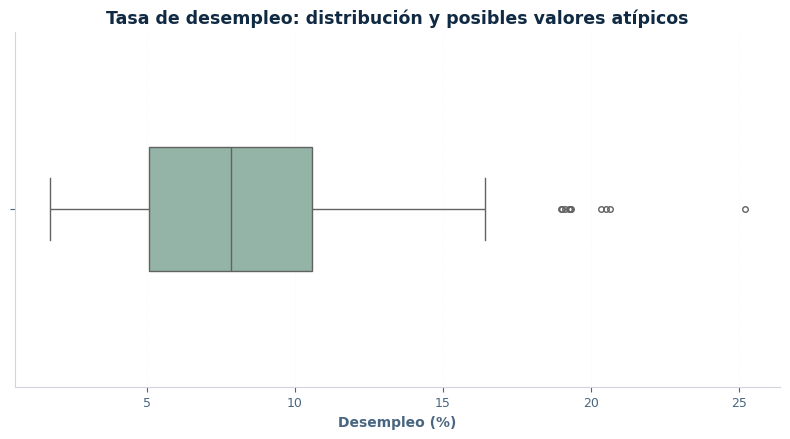

In [ ]:
# Diagrama de caja de la tasa de desempleo.
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.boxplot(
    x=lfh["unemployment_pct"].dropna(),
    ax=ax,
    color="#8FB9A8",
    width=0.35,
    fliersize=4
)

ax.set_title("Tasa de desempleo: distribución y posibles valores atípicos")
ax.set_xlabel("Desempleo (%)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Regla exploratoria de 1.5 × IQR para señalar posibles valores extremos.
# Se calcula el IQR de desempleo y se aplica a esa misma variable.
desempleo = lfh["unemployment_pct"].dropna()
Q1 = desempleo.quantile(0.25)
Q3 = desempleo.quantile(0.75)
IQR = Q3 - Q1

limite_superior_desempleo = Q3 + 1.5 * IQR
atipicos_desempleo = lfh[
    lfh["unemployment_pct"] > limite_superior_desempleo
]

display(
    atipicos_desempleo[["country", "year", "unemployment_pct"]]
    .sort_values("unemployment_pct", ascending=False)
)


,country,year,unemployment_pct
2638,St. Lucia,2020,25.22
2665,St. Vincent and the Grenadines,2020,20.64
2639,St. Lucia,2021,20.51
2666,St. Vincent and the Grenadines,2021,20.36
2636,St. Lucia,2018,19.33
2667,St. Vincent and the Grenadines,2022,19.28
2664,St. Vincent and the Grenadines,2019,19.25
2635,St. Lucia,2017,19.14
2662,St. Vincent and the Grenadines,2017,19.02
2663,St. Vincent and the Grenadines,2018,19.00


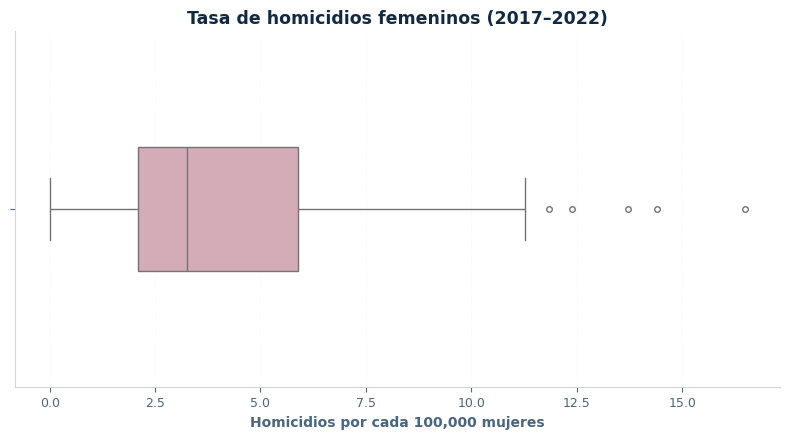

In [ ]:
# Diagrama de caja de la tasa de homicidios femeninos.
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.boxplot(
    x=lfh["female_homicide_rate"].dropna(),
    ax=ax,
    color="#D9A6B5",
    width=0.35,
    fliersize=4
)

ax.set_title("Tasa de homicidios femeninos (2017–2022)")
ax.set_xlabel("Homicidios por cada 100,000 mujeres")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()


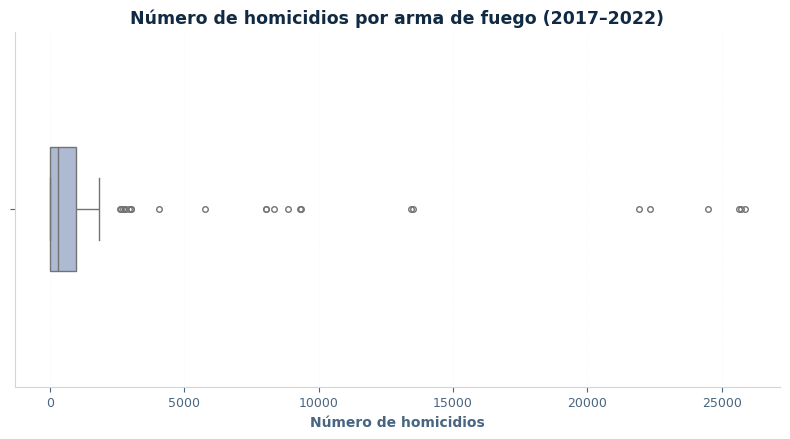

In [ ]:
# Diagrama de caja del número de homicidios por arma de fuego.
# Se conserva la escala original: los conteos absolutos también dependen
# del tamaño de la población y no equivalen a una tasa.
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.boxplot(
    x=lfh["firearm_homicides"].dropna(),
    ax=ax,
    color="#A8B8D8",
    width=0.35,
    fliersize=4
)

ax.set_title("Número de homicidios por arma de fuego (2017–2022)")
ax.set_xlabel("Número de homicidios")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()


In [ ]:
# Detección de posibles valores atípicos en la tasa de homicidios masculinos
# mediante la regla de 1.5 veces el rango intercuartílico (IQR).
tasa = lfh["male_homicide_rate"].dropna()
Q1 = tasa.quantile(0.25)
Q3 = tasa.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

atipicos = lfh[
    (lfh["male_homicide_rate"] < limite_inferior) |
    (lfh["male_homicide_rate"] > limite_superior)
]

print(f"Límite inferior: {limite_inferior:.2f}")
print(f"Límite superior: {limite_superior:.2f}")
print(f"Observaciones señaladas: {len(atipicos)}")

display(
    atipicos[["country", "year", "male_homicide_rate"]]
    .sort_values("male_homicide_rate", ascending=False)
)


Límite inferior: -38.68
Límite superior: 103.11
Observaciones señaladas: 2


,country,year,male_homicide_rate
897,El Salvador,2017,117.495
1440,Jamaica,2017,106.530


In [ ]:
# Detección de posibles valores atípicos en la tasa de homicidios masculinos
# mediante la regla de 1.5 veces el rango intercuartílico (IQR).
tasa = lfh["male_homicide_rate"].dropna()
Q1 = tasa.quantile(0.25)
Q3 = tasa.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

atipicos = lfh[
    (lfh["male_homicide_rate"] < limite_inferior) |
    (lfh["male_homicide_rate"] > limite_superior)
]

print(f"Límite inferior: {limite_inferior:.2f}")
print(f"Límite superior: {limite_superior:.2f}")
print(f"Observaciones señaladas: {len(atipicos)}")

display(
    atipicos[["country", "year", "male_homicide_rate"]]
    .sort_values("male_homicide_rate", ascending=False)
)


Límite inferior: -38.68
Límite superior: 103.11
Observaciones señaladas: 2


,country,year,male_homicide_rate
897,El Salvador,2017,117.495
1440,Jamaica,2017,106.530


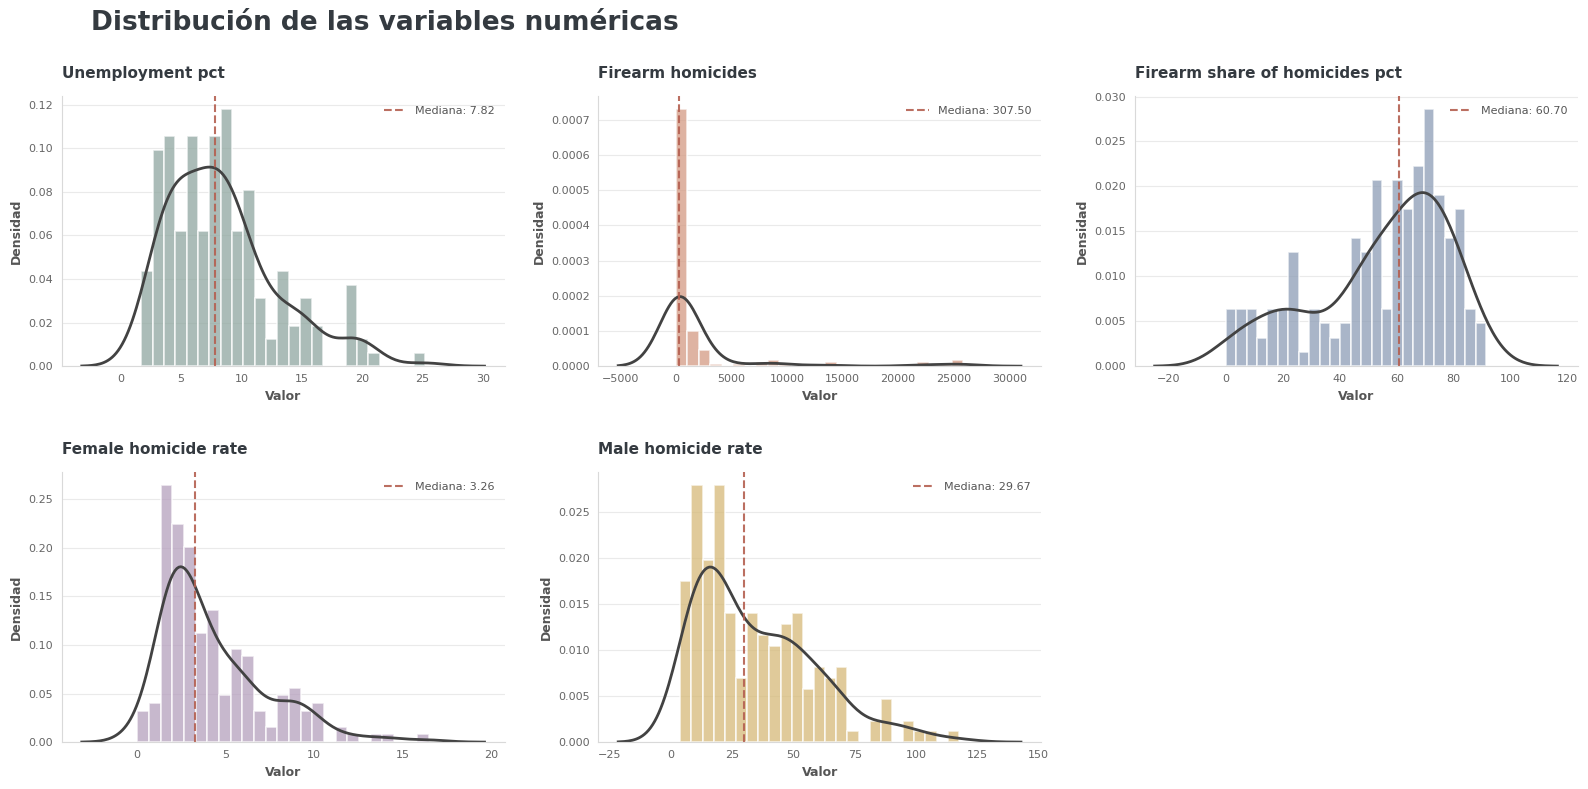

In [ ]:
import math
import seaborn as sns
# GRÁFICO: Distribución de las variables numéricas de LFH

# 1. Seleccionar variables numéricas
variables = [
    col for col in variables_revision
    if col != "year"
    and pd.api.types.is_numeric_dtype(lfh[col])
    and not pd.api.types.is_bool_dtype(lfh[col])
    and lfh[col].notna().any()
]

# 2. Paleta de colores
colores = [
    "#8FA6A0",  # Verde salvia
    "#D49A83",  # Terracota
    "#8D9DB6",  # Azul grisáceo
    "#B5A0BD",  # Lavanda
    "#D6B978",  # Mostaza suave
    "#A9B8CE",  # Azul pastel
    "#C58F91",  # Rosa viejo
    "#9BAE83"   # Verde olivo
]

# 3. Configuración de la figura
ncols = 3
nrows = math.ceil(len(variables) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(16, 4 * nrows),
    squeeze=False
)

fig.patch.set_facecolor("white")

# 4. Crear histogramas y curvas de densidad
for i, col in enumerate(variables):

    ax = axes.flat[i]
    datos = lfh[col].dropna()
    color = colores[i % len(colores)]

    # Histograma en escala de densidad
    ax.hist(
        datos,
        bins=25,
        density=True,
        color=color,
        edgecolor="white",
        linewidth=1.2,
        alpha=0.75
    )

    # Curva de densidad KDE
    if datos.nunique() > 1:
        sns.kdeplot(
            data=datos,
            ax=ax,
            color="#424242",
            linewidth=2,
            fill=False
        )

    # Línea de la mediana
    mediana = datos.median()

    ax.axvline(
        mediana,
        color="#B45F50",
        linestyle="--",
        linewidth=1.5,
        alpha=0.9,
        label=f"Mediana: {mediana:,.2f}"
    )

    # Título
    ax.set_title(
        col.replace("_", " ").capitalize(),
        fontsize=11,
        fontweight="semibold",
        color="#343A40",
        loc="left",
        pad=13
    )

    # Etiquetas
    ax.set_xlabel("Valor", fontsize=9, color="#555555")
    ax.set_ylabel("Densidad", fontsize=9, color="#555555")

    # Fondo blanco
    ax.set_facecolor("white")

    # Cuadrícula discreta
    ax.grid(
        axis="y",
        color="#EAEAEA",
        linestyle="-",
        linewidth=0.8
    )
    ax.set_axisbelow(True)

    # Eliminar bordes superiores y derechos
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D9D9D9")
    ax.spines["bottom"].set_color("#D9D9D9")

    # Estilo de los ejes
    ax.tick_params(
        axis="both",
        labelsize=8,
        colors="#666666",
        length=0,
        pad=6
    )

    # Leyenda
    ax.legend(
        fontsize=8,
        frameon=False,
        loc="upper right",
        labelcolor="#555555"
    )

# 5. Eliminar paneles vacíos
for j in range(len(variables), len(axes.flat)):
    fig.delaxes(axes.flat[j])

# 6. Título general
fig.suptitle(
    "Distribución de las variables numéricas",
    fontsize=19,
    fontweight="bold",
    color="#343A40",
    x=0.06,
    ha="left",
    y=0.98
)

# 7. Ajustes finales
plt.tight_layout(
    rect=[0, 0, 1, 0.98],
    h_pad=2.8,
    w_pad=2
)

plt.show()


###**3.5 Imputación de valores faltantes mediante la mediana**
Decisión de transformación 2 — imputación por mediana. Para las cinco variables seleccionadas (con menos del 20% de datos faltantes) se reemplazan los valores faltantes por la mediana calculada con las observaciones disponibles de cada variable dentro de la muestra de América Latina y el Caribe (2017–2022).

La elección de la mediana se apoya en el diagnóstico anterior: los diagramas de caja y los histogramas permiten detectar asimetrías y observaciones extremas. A diferencia de la media, la mediana es menos sensible a valores muy grandes o pequeños, por lo que puede ser un resumen más robusto en variables como los conteos y las tasas de homicidio. Esta imputación es sencilla y conserva el número de filas para los análisis posteriores.

Precaución e interpretación. La mediana global de cada variable no incorpora diferencias entre países ni la evolución temporal. Por tanto, los valores imputados no representan mediciones observadas y pueden reducir artificialmente la dispersión, concentrando observaciones en el valor central. La imputación se aplica solo a las cinco variables indicadas; no se modifican los valores observados ni se imputan las columnas excluidas. Los resultados que utilicen estas variables deben interpretarse considerando esta limitación.

In [ ]:
# Se conserva una copia sin imputar para poder comparar y auditar el tratamiento.
lfh_sin_imputar = lfh.copy()
lfh_imputada = lfh.copy()

# Resumen de faltantes, mediana utilizada y número de valores imputados.
resumen_imputacion = []

for variable in variables_revision:
    faltantes_antes = lfh_sin_imputar[variable].isna().sum()
    mediana = lfh_sin_imputar[variable].median()

    # Si una variable estuviera completamente vacía, no existiría una mediana válida.
    # En ese caso se conserva el faltante y se informa en la tabla.
    if pd.notna(mediana):
        lfh_imputada[variable] = lfh_imputada[variable].fillna(mediana)

    faltantes_despues = lfh_imputada[variable].isna().sum()

    resumen_imputacion.append({
        "Variable": variable,
        "Faltantes antes": faltantes_antes,
        "Mediana utilizada": mediana,
        "Valores imputados": faltantes_antes - faltantes_despues,
        "Faltantes después": faltantes_despues
    })

resumen_imputacion = pd.DataFrame(resumen_imputacion)

display(
    resumen_imputacion.style.format({
        "Faltantes antes": "{:,.0f}",
        "Mediana utilizada": "{:,.2f}",
        "Valores imputados": "{:,.0f}",
        "Faltantes después": "{:,.0f}"
    }).background_gradient(
        subset=["Valores imputados"], cmap="YlGn"
    )
)

# Comprobación: no deben quedar faltantes en las variables imputadas,
# salvo que alguna variable estuviera completamente vacía.
print("Faltantes después de la imputación:")
display(lfh_imputada[variables_revision].isna().sum().to_frame("Faltantes"))

# A partir de este punto, lfh contiene la versión imputada que utilizará la sección 4.
# La versión original permanece disponible en lfh_sin_imputar.
lfh = lfh_imputada.copy()

,Variable,Faltantes antes,Mediana utilizada,Valores imputados,Faltantes después
0,unemployment_pct,32,7.82,32,0
1,firearm_homicides,31,307.50,31,0
2,firearm_share_of_homicides_pct,31,60.70,31,0
3,female_homicide_rate,14,3.26,14,0
4,male_homicide_rate,14,29.67,14,0


Faltantes después de la imputación:


,Faltantes
unemployment_pct,0
firearm_homicides,0
firearm_share_of_homicides_pct,0
female_homicide_rate,0
male_homicide_rate,0


Interpretación de la imputación. La tabla reporta, para cada variable, cuántos valores faltaban, cuál fue la mediana observada utilizada y cuántos registros se completaron. La columna de faltantes después permite comprobar el resultado del procedimiento. Si una variable no tiene ninguna observación válida, no se inventa una mediana: sus faltantes permanecen y deben atenderse antes de aplicar métodos que requieran datos completos.

La imputación conserva el tamaño de la muestra, pero no añade información nueva. En particular, puede reducir la variabilidad y alterar correlaciones o distribuciones; por eso se conserva lfh_sin_imputar como respaldo y conviene contrastar los resultados principales con la base original cuando la interpretación sea sensible a esta decisión.

## **4. Visualización de datos**
Seleccionamos las siguientes gráficas para observar el comportamiento de la violencia homicida en América Latina durante el periodo 2017–2022, así como las diferencias y variaciones que existen entre los países de la región. A través de estas visualizaciones buscamos identificar tendencias, patrones y posibles relaciones entre la violencia homicida y algunos factores socioeconómicos. Esto nos permitirá comprender mejor la evolución del fenómeno y obtener elementos para responder nuestras preguntas de investigación. Cada gráfica se acompaña de una interpretación de los resultados

### ¿Qué variables sociales, económicas y demográficas están relacionadas con las tasas de homicidios por país en Latinoamérica? | Los 10 países mas peligrosos en la región

### **4.1 Comparación de América Latina y el Caribe con el resto del mundo de 2017 a 2022**

En este apartado se utilizan dos visualizaciones:

**Diagrama de caja y bigotes (Box Plot):** permite comparar la distribución de las tasas de homicidio por región, identificando sus medianas, dispersión y valores atípicos.

- **¿Qué información podemos obtener?**
Nos permite comparar la distribución de las tasas de homicidio entre las distintas regiones del mundo, identificar cuáles presentan mayores niveles de violencia homicida y observar las diferencias en su variabilidad.

**Gráfica de barras horizontales apiladas:** permite comparar las tasas medianas de homicidios con arma de fuego y por otros medios en las distintas regiones.

- **¿Qué información podemos obtener?**
Nos permite comparar las tasas medianas de homicidios cometidos con armas de fuego y por otros medios en cada región. Con ella podemos identificar el peso que tienen las armas de fuego en la violencia letal y observar el comportamiento en América Latina y el Caribe.

**¿Por qué utilizamos una escala logarítmica?**

Utilizamos una escala logarítmica debido a que las tasas de homicidio presentan diferencias considerables entre las regiones. Esta transformación permite visualizar los valores pequeños y grandes dentro de una misma gráfica, evitando que las regiones con tasas más elevadas compriman visualmente al resto. De esta manera, podemos comparar mejor la distribución, dispersión y mediana de las tasas de homicidio, así como identificar diferencias entre regiones que serían menos evidentes en una escala lineal.

/tmp/ipykernel_1140/3585362849.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


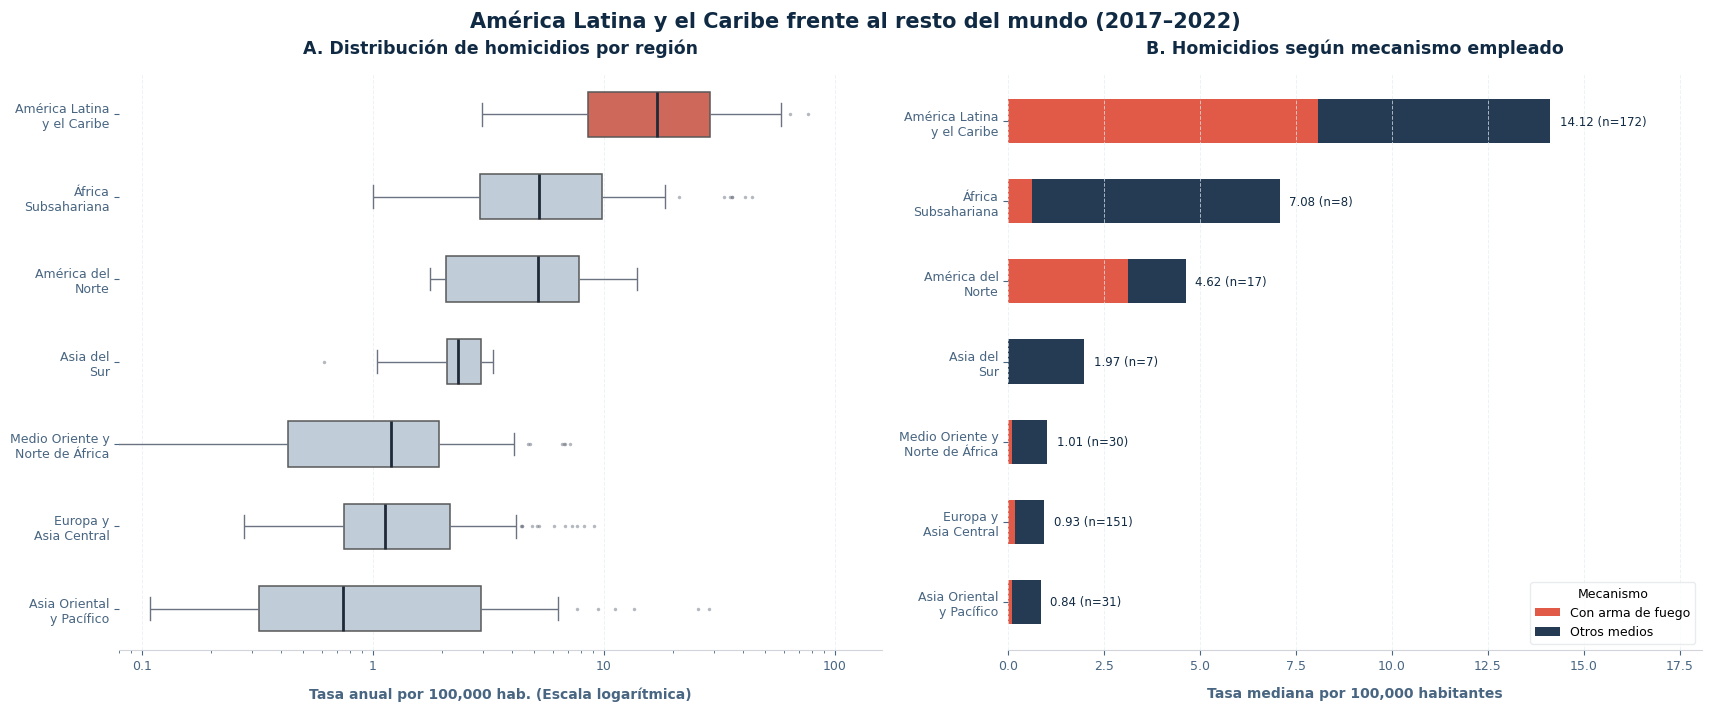

In [ ]:
# Configuración general

# Paleta Editorial Unificada
PALETA_ESTUDIO = {
    'primario': '#E05A47',
    'secundario': '#1D9A78',
    'neutro_oscuro': '#243B53',
    'neutro_claro': '#BCCCDC',
    'acento_mujer': '#9B2C67',
    'texto': '#102A43',
    'subtexto': '#486581',
    'grid': '#E6ECF2',
    'fondo': '#FFFFFF'
}

# Estilo global
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'axes.titleweight': 'bold',
    'axes.titlesize': 12.5,
    'axes.titlecolor': PALETA_ESTUDIO['texto'],
    'axes.labelsize': 10,
    'axes.labelweight': 'semibold',
    'axes.labelcolor': PALETA_ESTUDIO['subtexto'],
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'xtick.color': PALETA_ESTUDIO['subtexto'],
    'ytick.color': PALETA_ESTUDIO['subtexto'],
    'figure.facecolor': PALETA_ESTUDIO['fondo'],
    'axes.facecolor': PALETA_ESTUDIO['fondo'],
    'axes.edgecolor': '#D1D5DB',
    'axes.linewidth': 0.8,
    'grid.color': PALETA_ESTUDIO['grid'],
    'grid.linestyle': '--',
    'grid.linewidth': 0.7,
    'legend.frameon': True,
    'legend.facecolor': '#FFFFFF',
    'legend.edgecolor': '#E5E7EB',
    'legend.fontsize': 9
})

fh_10 = fh[fh['year'].between(2017, 2022)].copy()
fh_10['non_firearm_homicide_rate'] = np.where(
    fh_10['homicide_rate'].notnull() & fh_10['firearm_homicide_rate'].notnull(),
    (fh_10['homicide_rate'] - fh_10['firearm_homicide_rate']).clip(lower=0),
    np.nan
)

region_es_map = {
    'Latin America & Caribbean': 'América Latina\ny el Caribe',
    'North America': 'América del\nNorte',
    'Sub-Saharan Africa': 'África\nSubsahariana',
    'South Asia': 'Asia del\nSur',
    'Middle East, North Africa, Afghanistan & Pakistan': 'Medio Oriente y\nNorte de África',
    'Europe & Central Asia': 'Europa y\nAsia Central',
    'East Asia & Pacific': 'Asia Oriental\ny Pacífico'
}
fh_10['region_es'] = fh_10['region'].map(region_es_map)

order_reg = (
    fh_10.groupby('region_es')['homicide_rate']
    .median().sort_values(ascending=False).index
)

palette_reg = [
    PALETA_ESTUDIO['primario'] if r == 'América Latina\ny el Caribe'
    else PALETA_ESTUDIO['neutro_claro']
    for r in order_reg
]

fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.1, 1]}, constrained_layout=True)

# --- A. BOXPLOT ---
sub_box = fh_10[fh_10['homicide_rate'] > 0].copy()
sns.boxplot(
    data=sub_box, x='homicide_rate', y='region_es', order=order_reg,
    ax=axes[0], palette=palette_reg, width=0.55, fliersize=2.5, linewidth=1.1,
    medianprops=dict(color='#1F2937', linewidth=2),
    whiskerprops=dict(color='#6B7280', linewidth=1),
    capprops=dict(color='#6B7280', linewidth=1),
    flierprops=dict(marker='o', markerfacecolor='#6B7280', alpha=0.5, markeredgecolor='none')
)
axes[0].set_xscale('log')
axes[0].set_xlim(0.08, 160)
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:g}"))
axes[0].set_xlabel('Tasa anual por 100,000 hab. (Escala logarítmica)', labelpad=10)
axes[0].set_ylabel('')
axes[0].set_title('A. Distribución de homicidios por región', pad=14)
axes[0].grid(axis='x', alpha=0.7)
axes[0].grid(axis='y', visible=False)
sns.despine(ax=axes[0], left=True)

# --- B. BARRAS APILADAS ---
paired = fh_10.dropna(subset=['firearm_homicide_rate', 'non_firearm_homicide_rate']).copy()
comp_b = (
    paired.groupby('region_es')
    .agg(n_obs=('homicide_rate', 'count'),
         med_arma=('firearm_homicide_rate', 'median'),
         med_otros=('non_firearm_homicide_rate', 'median'))
    .reindex(order_reg[::-1])
)

y_pos = np.arange(len(comp_b))
axes[1].barh(y_pos, comp_b['med_arma'], color=PALETA_ESTUDIO['primario'], height=0.55, label='Con arma de fuego')
axes[1].barh(y_pos, comp_b['med_otros'], left=comp_b['med_arma'], color=PALETA_ESTUDIO['neutro_oscuro'], height=0.55, label='Otros medios')

for idx, (_, row) in enumerate(comp_b.iterrows()):
    total = row['med_arma'] + row['med_otros']
    axes[1].text(total + 0.25, idx, f"{total:.2f} (n={int(row['n_obs'])})", va='center', fontsize=8.5, color=PALETA_ESTUDIO['texto'])

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(comp_b.index)
max_total = (comp_b['med_arma'] + comp_b['med_otros']).max()
axes[1].set_xlim(0, max_total * 1.28)
axes[1].set_xlabel('Tasa mediana por 100,000 habitantes', labelpad=10)
axes[1].set_ylabel('')
axes[1].set_title('B. Homicidios según mecanismo empleado', pad=14)
axes[1].grid(axis='x', alpha=0.7)
axes[1].grid(axis='y', visible=False)
axes[1].legend(loc='lower right', title='Mecanismo', title_fontsize=9)
sns.despine(ax=axes[1], left=True)

fig.suptitle('América Latina y el Caribe frente al resto del mundo (2017–2022)', fontsize=15, fontweight='bold', color=PALETA_ESTUDIO['texto'])
plt.show()

**Interpretación:** Al comparar las tasas de homicidio entre las distintas regiones, América Latina y el Caribe destaca por presentar la mediana más elevada, cercana a 17 homicidios por cada 100,000 habitantes. También se observa una dispersión considerable en sus datos, lo que refleja diferencias importantes entre los países de la región. Por otro lado, al comparar las tasas medianas según el mecanismo empleado, América Latina y el Caribe registra el valor más alto, con una suma de 14.12 homicidios por cada 100,000 habitantes entre ambos mecanismos. En este resultado, los homicidios cometidos con armas de fuego representan el componente más grande, a diferencia de regiones como África Subsahariana, donde predominan los homicidios por otros medios. En general, ambas gráficas muestran que América Latina y el Caribe presenta niveles de violencia homicida considerablemente superiores a los de otras regiones, así como una importante participación de las armas de fuego en este fenómeno.

### **4.2 Distribución de las tasas de homicidio por país en América Latina (2017–2022)**

**Diagrama de caja y bigotes (Box Plot):** permite observar la distribución de las tasas de homicidio de cada país durante el periodo 2017–2022, identificando su mediana, variabilidad y posibles valores atípicos.

- **¿Qué información podemos obtener?** Nos permite identificar qué países presentan las tasas de homicidio más elevadas y cuáles mantienen niveles relativamente bajos. También podemos observar en qué países existe una mayor variación de las tasas a lo largo del periodo, así como aquellos que presentan valores atípicos. Esto nos ayuda a reconocer las diferencias entre países y analizar cómo ha sido el comportamiento de la violencia homicida en la región.

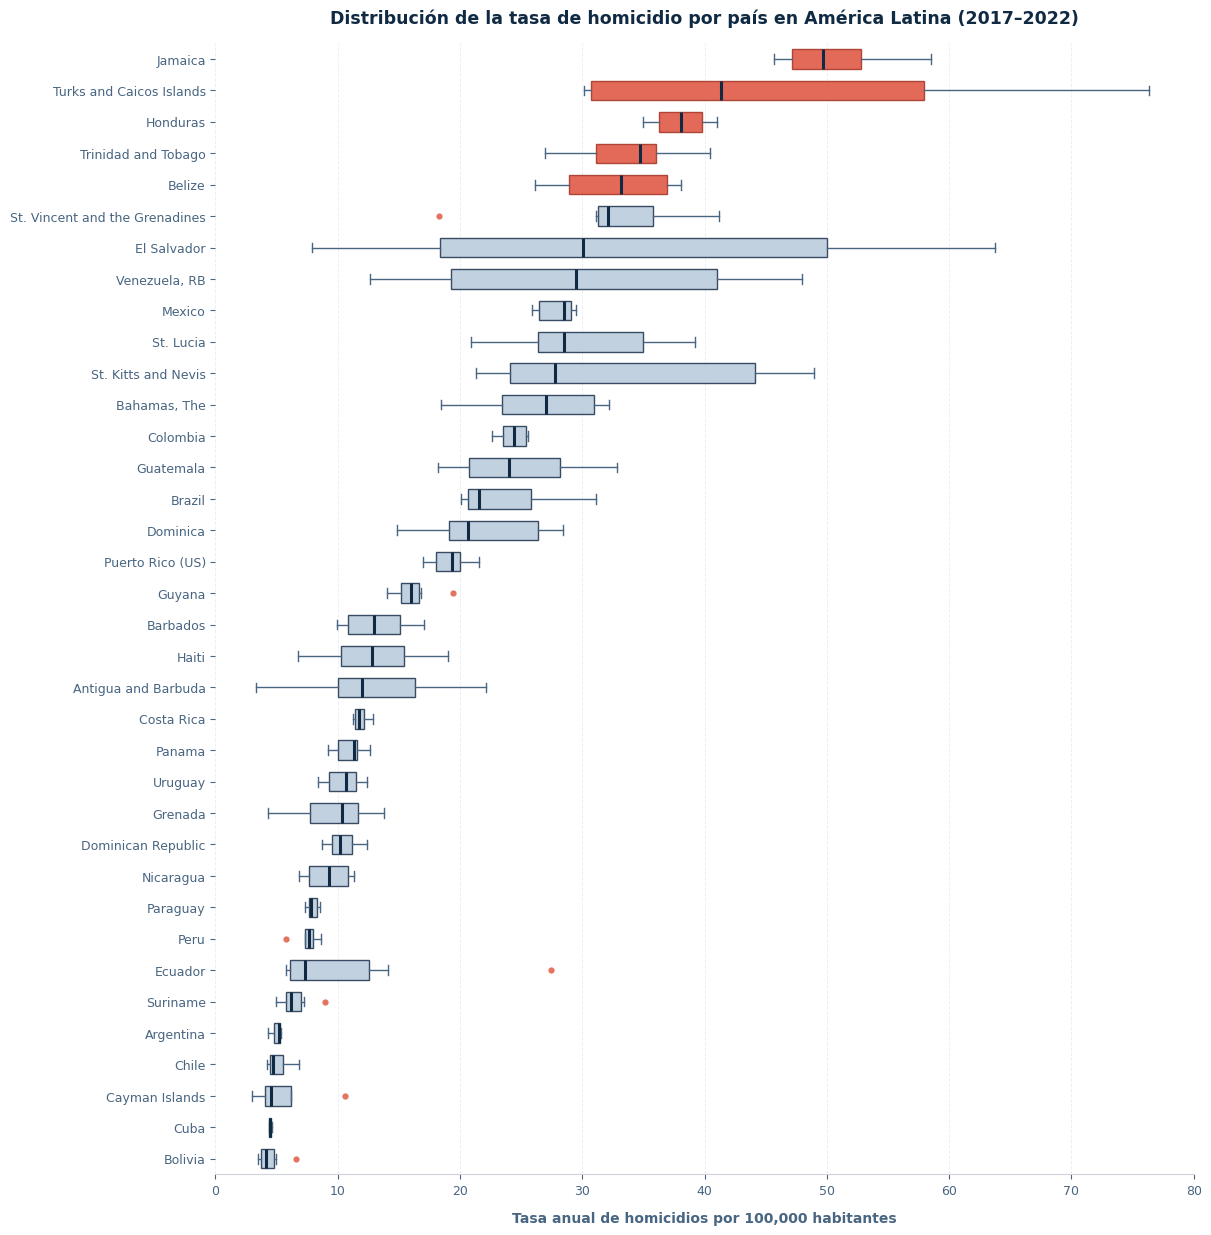

In [ ]:
tabla_analitica = lfh
orden = (tabla_analitica.groupby("country")["homicide_rate"]
         .median().sort_values(ascending=False).index)

muestras = [
    tabla_analitica.loc[tabla_analitica["country"] == c, "homicide_rate"].dropna().values
    for c in orden
]

altura_fig = max(9, len(orden) * 0.34)
fig, ax = plt.subplots(figsize=(12, altura_fig), constrained_layout=True)

bp = ax.boxplot(
    muestras, vert=False, patch_artist=True, showfliers=True, widths=0.62,
    medianprops=dict(color=PALETA_ESTUDIO['texto'], linewidth=2.2),
    boxprops=dict(facecolor=PALETA_ESTUDIO['neutro_claro'], edgecolor=PALETA_ESTUDIO['neutro_oscuro'], linewidth=1, alpha=0.9),
    whiskerprops=dict(color=PALETA_ESTUDIO['subtexto'], linewidth=1),
    capprops=dict(color=PALETA_ESTUDIO['subtexto'], linewidth=1),
    flierprops=dict(marker="o", markersize=4.5, markerfacecolor=PALETA_ESTUDIO['primario'], markeredgecolor="none", alpha=0.85)
)

# Resaltar en coral los 5 países con mayor mediana
for i in range(min(5, len(bp['boxes']))):
    bp['boxes'][i].set_facecolor(PALETA_ESTUDIO['primario'])
    bp['boxes'][i].set_edgecolor('#A63A2B')

ax.set_yticks(range(1, len(orden) + 1))
ax.set_yticklabels(orden, fontsize=9)
ax.invert_yaxis()
ax.set_title("Distribución de la tasa de homicidio por país en América Latina (2017–2022)", pad=14)
ax.set_xlabel("Tasa anual de homicidios por 100,000 habitantes", labelpad=10)
ax.set_xlim(left=0)
ax.grid(axis='x', alpha=0.8)
ax.grid(axis='y', visible=False)
sns.despine(ax=ax, left=True)

plt.show()

**Interpretación:** Analizando las tasas de homicidio por país, se observa que América Latina y el Caribe está lejos de ser una región homogénea. Las medianas muestran diferencias importantes: Jamaica, Islas Turcas y Caicos, Honduras, Trinidad y Tobago y Belice se encuentran entre los países con mayores tasas, mientras que Bolivia, Cuba, Chile y Argentina presentan niveles considerablemente menores. La diferencia entre los países con las tasas más altas y más bajas es cercana a diez veces.

Además de comparar los niveles de homicidio, los diagramas de caja permiten observar cómo cambiaron las tasas durante el periodo. Algunos países, como El Salvador, Venezuela e Islas Turcas y Caicos, presentan una variabilidad considerable, mientras que otros, como Honduras, Jamaica, México y Costa Rica, mantienen niveles más estables. Esto es importante porque dos países pueden tener medianas similares, pero comportamientos muy distintos a lo largo de los años.

### **4.3 Distribución de las tasas de homicidio por país en América Latina (2017–2022)**

**Gráfica de barras: mediana de las tasas de homicidio por país en América Latina (2017–2022):** presenta las tasas medianas de homicidio por cada 100,000 habitantes para los países de América Latina. Los países se ordenan de mayor a menor, lo que permite comparar sus niveles de violencia homicida durante el periodo analizado.

- **¿Qué información podemos obtener?** Nos permite identificar qué países presentan las tasas medianas de homicidio más elevadas y cuáles registran niveles relativamente bajos. También facilita reconocer las diferencias en la incidencia de la violencia homicida dentro de la región y observar qué países destacan por sus mayores niveles.

/tmp/ipykernel_1140/2156089620.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


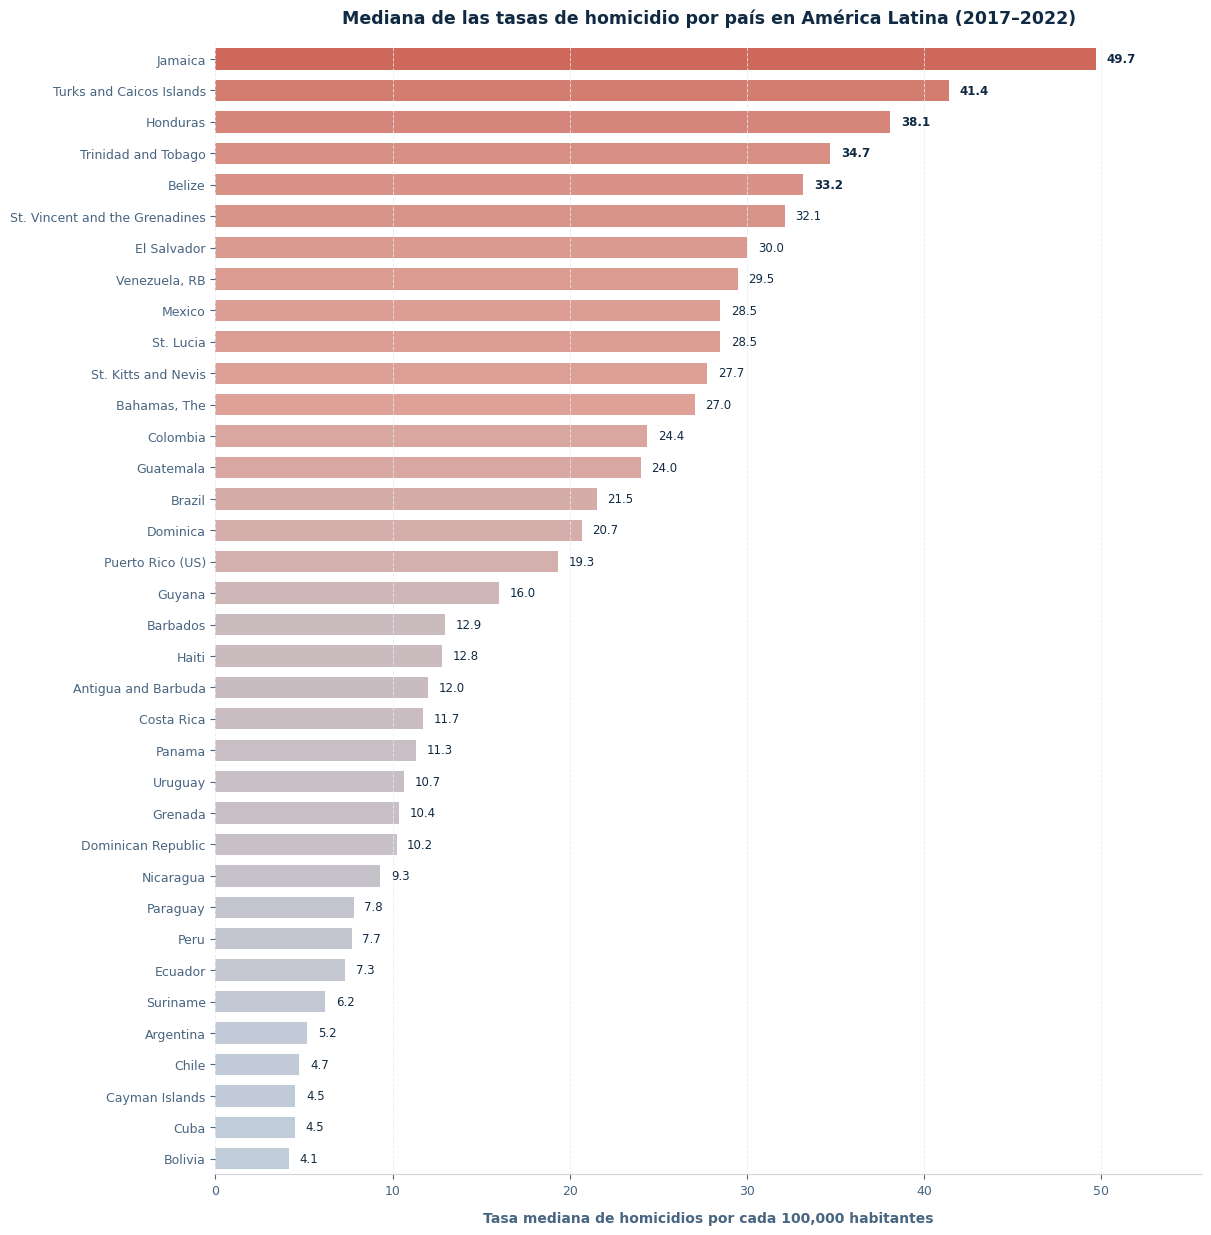

In [ ]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

ranking = (
    lfh.groupby("country")
       .agg(homicidios=("homicide_rate", "median"))
       .dropna()
       .sort_values("homicidios", ascending=False)
       .reset_index()
)

altura_fig = max(9, len(ranking) * 0.34)
fig, ax = plt.subplots(figsize=(12, altura_fig), constrained_layout=True)

# Degradado editorial: de azul niebla (tasas bajas) a coral intenso (tasas altas)
cmap_barras = LinearSegmentedColormap.from_list(
    "degradado_ranking",
    [PALETA_ESTUDIO['neutro_claro'], "#E8998D", PALETA_ESTUDIO['primario']],
    N=256
)

# Normalizar colores según el valor real de homicidios (o por posición en el ranking)
norm = Normalize(vmin=ranking['homicidios'].min(), vmax=ranking['homicidios'].max())
colores_difuminados = [cmap_barras(norm(val)) for val in ranking['homicidios']]

sns.barplot(
    data=ranking, y="country", x="homicidios",
    palette=colores_difuminados, ax=ax, width=0.68
)

# Etiquetas limpias al final de cada barra
for index, row in ranking.iterrows():
    ax.text(
        row['homicidios'] + 0.6, index, f"{row['homicidios']:.1f}",
        va='center', fontsize=8.5, color=PALETA_ESTUDIO['texto'],
        fontweight='bold' if index < 5 else 'normal'
    )

ax.set_xlim(0, ranking['homicidios'].max() * 1.12)
ax.set_title("Mediana de las tasas de homicidio por país en América Latina (2017–2022)", pad=14)
ax.set_xlabel("Tasa mediana de homicidios por cada 100,000 habitantes", labelpad=10)
ax.set_ylabel("")
ax.grid(axis='x', alpha=0.8)
ax.grid(axis='y', visible=False)
sns.despine(ax=ax, left=True)

plt.show()

**Interpretación:** La gráfica muestra una diferencia bastante marcada entre los países de la región. Jamaica, Islas Turcas y Caicos y Honduras encabezan la lista, con tasas medianas cercanas o superiores a 38 homicidios por cada 100,000 habitantes. En el otro extremo, Bolivia, Cuba, Islas Caimán, Chile y Argentina presentan tasas por debajo de 5. Esto refleja que la violencia homicida se concentra con mayor intensidad en ciertos países, principalmente del Caribe y Centroamérica, mientras que en otros se mantiene en niveles mucho más bajos. Por lo tanto, no se puede hablar de un comportamiento general para toda América Latina y el Caribe, ya que las diferencias entre países son considerables.

### **4.4 Heterogeneidad intrarregional: cambios y trayectorias de la violencia homicida (2017–2022)**

En este apartado se utilizan dos visualizaciones integradas:

**Gráfica A. Comparación de las tasas medianas de homicidio entre dos trienios (2017–2019 y 2020–2022):** permite comparar los niveles de homicidio de cada país entre ambos periodos e identificar si hubo aumentos o disminuciones.

- **¿Qué información podemos obtener?** Nos permite identificar qué países registraron reducciones (líneas verdes) o incrementos (líneas naranjas) en sus tasas medianas de homicidio entre ambos trienios. Esto ayuda a reconocer los cambios en la violencia homicida dentro de América Latina y a observar si el comportamiento fue similar o distinto entre países.

**Gráfica B. Evolución anual de las tasas de homicidio en países seleccionados (2017–2022):** muestra el comportamiento anual de las tasas de homicidio a lo largo de los seis años en seis países clave de la región (El Salvador, Honduras, México, Brasil, Ecuador y Chile).

- **¿Qué información podemos obtener?** Nos permite identificar tendencias, repuntes y disminuciones año con año en cada país, así como comparar sus trayectorias. Esto ayuda a reconocer las diferencias en la evolución de la violencia homicida entre los países seleccionados y observar que no todos han seguido el mismo comportamiento durante el periodo analizado.
- **¿Por qué se seleccionaron estos países?** A partir de los cambios observados entre ambos trienios en la **Gráfica A**, se eligieron estos seis casos para profundizar en sus trayectorias anuales por las siguientes razones:
  - **México y Brasil:** Por su peso demográfico, ya que al ser los países con mayor población en América Latina concentran un volumen determinante de la violencia regional; además, en la Gráfica A muestran comportamientos distintos entre trienios: **México** presenta una variación mínima (casi estable alrededor de 28–29), mientras **Brasil** registra una disminución notable (bajando de ~27 a ~20).
  - **El Salvador:** Porque exhibe la reducción más drástica entre trienios de toda la región (pasando de una mediana superior a 53 a una cercana a 17), lo que permite examinar el impacto anual de las estrategias de seguridad implementadas durante la administración de Nayib Bukele.
  - **Honduras:** Como referente de los países que, pese a registrar una leve disminución entre trienios, se mantienen en el grupo con las tasas medianas más altas de la región (por encima de 35).
  - **Ecuador:** Porque destaca como el caso con el incremento más pronunciado entre ambos periodos (pasando de una mediana cercana a 6 a una superior a 14), justificando revisar en qué momento ocurrió ese quiebre.
  - **Chile:** Como punto de referencia de los países con las tasas más bajas de la región (ubicadas alrededor de 4 a 6).

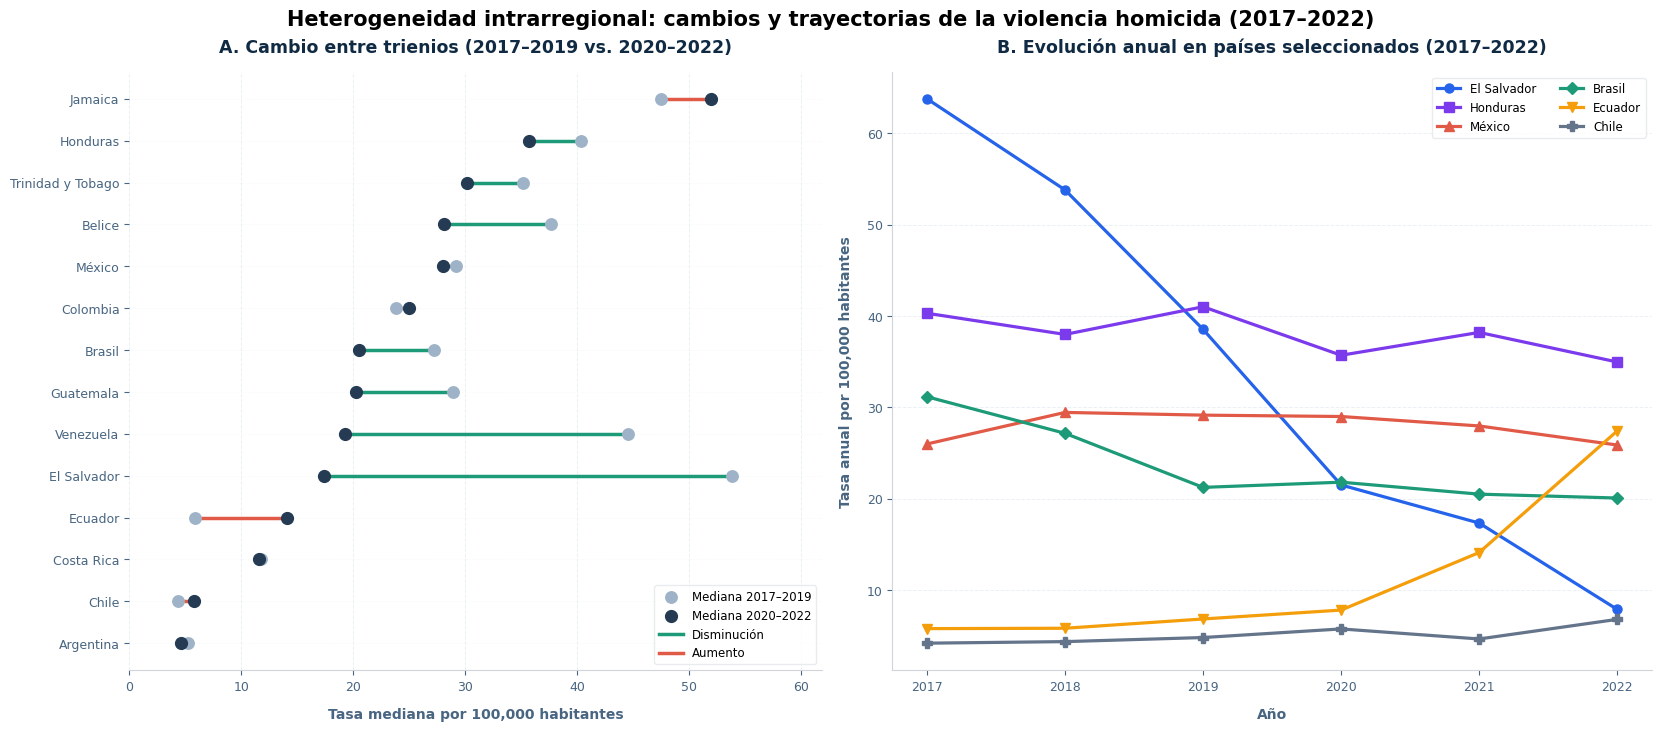

In [ ]:
piv_q = (
    lfh.assign(trienio=np.where(lfh['year'] <= 2019, '2017–2019', '2020–2022'))
    .pivot_table(index='country', columns='trienio', values='homicide_rate', aggfunc='median')
    .dropna(subset=['2017–2019', '2020–2022'])
)

sel_latam_dumb = [
    'El Salvador', 'Jamaica', 'Venezuela, RB', 'Honduras',
    'Belize', 'Trinidad and Tobago', 'Mexico', 'Colombia',
    'Brazil', 'Guatemala', 'Ecuador', 'Costa Rica',
    'Argentina', 'Chile'
]

piv_sel = piv_q.loc[[c for c in sel_latam_dumb if c in piv_q.index]].sort_values('2020–2022', ascending=True)

nombres_es = {
    'Mexico': 'México', 'Brazil': 'Brasil', 'Venezuela, RB': 'Venezuela',
    'Trinidad and Tobago': 'Trinidad y Tobago', 'El Salvador': 'El Salvador',
    'Jamaica': 'Jamaica', 'Honduras': 'Honduras', 'Belize': 'Belice',
    'Colombia': 'Colombia', 'Guatemala': 'Guatemala', 'Ecuador': 'Ecuador',
    'Costa Rica': 'Costa Rica', 'Argentina': 'Argentina', 'Chile': 'Chile'
}

fig, axes = plt.subplots(1, 2, figsize=(16.5, 7.2), gridspec_kw={'width_ratios': [1.05, 1.15]}, constrained_layout=True)

# --- GRÁFICA A. COMPARACIÓN ENTRE TRIENIOS ---
y_d = np.arange(len(piv_sel))

for idx, (_, row) in enumerate(piv_sel.iterrows()):
    color_line = PALETA_ESTUDIO['primario'] if row['2020–2022'] > row['2017–2019'] else PALETA_ESTUDIO['secundario']
    axes[0].plot([row['2017–2019'], row['2020–2022']], [idx, idx], color=color_line, linewidth=2.5, zorder=2)

axes[0].scatter(piv_sel['2017–2019'], y_d, color='#9FB3C8', s=68, zorder=3, label='Mediana 2017–2019')
axes[0].scatter(piv_sel['2020–2022'], y_d, color=PALETA_ESTUDIO['neutro_oscuro'], s=72, zorder=4, label='Mediana 2020–2022')
axes[0].plot([], [], color=PALETA_ESTUDIO['secundario'], linewidth=2.5, label='Disminución')
axes[0].plot([], [], color=PALETA_ESTUDIO['primario'], linewidth=2.5, label='Aumento')

axes[0].set_yticks(y_d)
axes[0].set_yticklabels([nombres_es.get(c, c) for c in piv_sel.index])
axes[0].set_xlim(0, max(piv_sel[['2017–2019', '2020–2022']].max()) * 1.15)
axes[0].set_xlabel('Tasa mediana por 100,000 habitantes', labelpad=10)
axes[0].set_title('A. Cambio entre trienios (2017–2019 vs. 2020–2022)', pad=14)
axes[0].legend(loc='lower right', fontsize=8.5)
axes[0].grid(axis='x', alpha=0.8)
axes[0].grid(axis='y', linestyle=':', alpha=0.4)
sns.despine(ax=axes[0], left=True)

# --- GRÁFICA B. EVOLUCIÓN ANUAL ---
trayectorias = {
    'El Salvador': ('El Salvador', '#2563EB', 'o'),
    'Honduras': ('Honduras', '#7C3AED', 's'),
    'Mexico': ('México', PALETA_ESTUDIO['primario'], '^'),
    'Brazil': ('Brasil', PALETA_ESTUDIO['secundario'], 'D'),
    'Ecuador': ('Ecuador', '#F59E0B', 'v'),
    'Chile': ('Chile', '#64748B', 'P')
}

for c_en, (c_es, col, mk) in trayectorias.items():
    sub_c = lfh[lfh['country'] == c_en].sort_values('year')
    axes[1].plot(sub_c['year'], sub_c['homicide_rate'], label=c_es, color=col, marker=mk, markersize=6.5, linewidth=2.3)

axes[1].set_xticks(range(2017, 2023))
axes[1].set_xlabel('Año', labelpad=10)
axes[1].set_ylabel('Tasa anual por 100,000 habitantes', labelpad=10)
axes[1].set_title('B. Evolución anual en países seleccionados (2017–2022)', pad=14)
axes[1].legend(loc='upper right', ncol=2, fontsize=8.5)
axes[1].grid(axis='y', alpha=0.8)
axes[1].grid(axis='x', visible=False)
sns.despine(ax=axes[1])

fig.suptitle('Heterogeneidad intrarregional: cambios y trayectorias de la violencia homicida (2017–2022)', fontsize=15, fontweight='bold')
plt.show()

**Interpretación:** La comparación de las tasas medianas entre los trienios 2017–2019 y 2020–2022 muestra que la violencia homicida disminuyó en varios países, aunque también se identifican casos en los que aumentó. El Salvador y Venezuela destacan por sus reducciones, mientras que Ecuador presenta uno de los incrementos más importantes, al pasar de una mediana cercana a 6 a otra de aproximadamente 14 homicidios por cada 100,000 habitantes. En países como México, las tasas se mantienen relativamente similares entre ambos periodos.

La evolución anual permite observar estas diferencias con mayor detalle. El Salvador presenta una caída pronunciada durante los seis años, mientras que Honduras conserva tasas elevadas con pocas variaciones. México muestra un comportamiento relativamente estable y Brasil registra una disminución. En contraste, Ecuador presenta un aumento importante hacia 2022. Estos resultados muestran que no existe una sola tendencia para toda la región: mientras algunos países han logrado reducciones importantes, otros enfrentan un incremento de la violencia homicida.

### **4.5 Brecha de género en homicidios y violencia de pareja íntima (2017–2022)**

**Grafico de barras:** este apartado se utiliza una visualización para comparar las diferencias en las tasas de victimización entre hombres y mujeres, tanto en homicidios como en violencia de pareja íntima (IPV), entre América Latina y el Caribe y el resto del mundo.


- **¿Qué información podemos obtener?** Nos permite identificar las diferencias entre hombres y mujeres según el tipo de violencia, así como contrastar si las brechas de género presentan un comportamiento distinto en América Latina y el resto del mundo. También permite observar cómo cambia el patrón de victimización entre los homicidios y la violencia de pareja íntima.

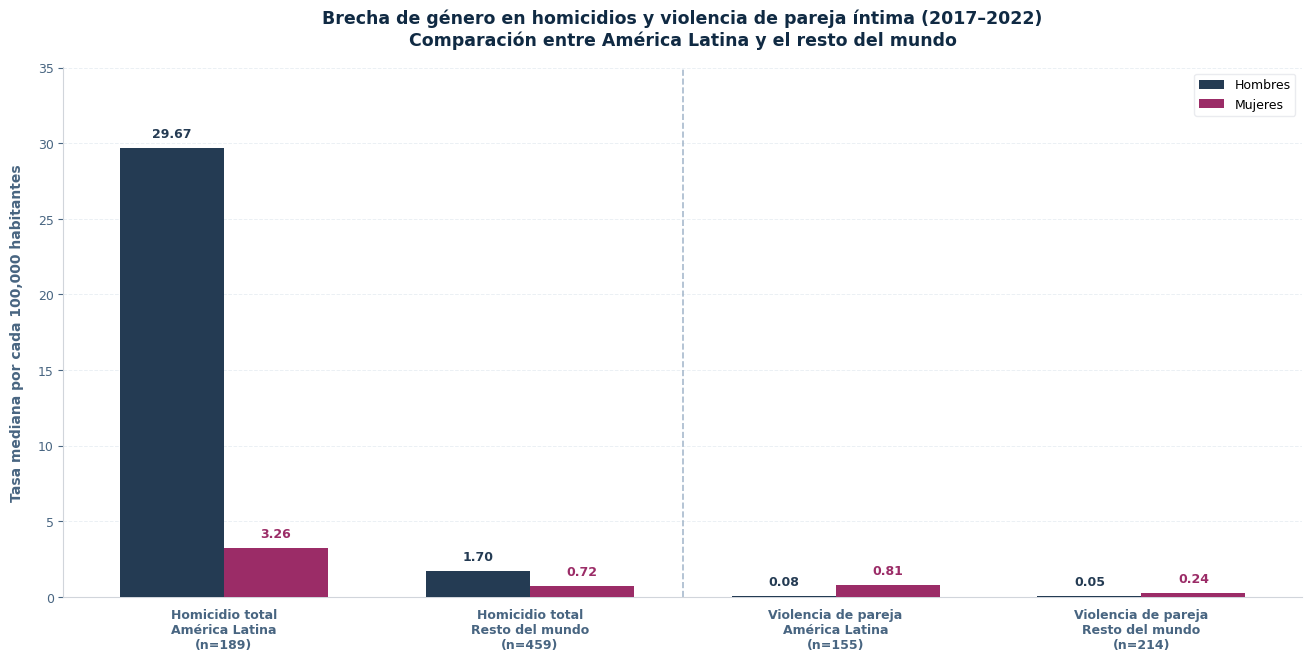

In [ ]:
fh_17_22 = fh[fh['year'].between(2017, 2022)].copy()

latam_sex = fh_17_22[fh_17_22['region'] == 'Latin America & Caribbean'].dropna(subset=['male_homicide_rate', 'female_homicide_rate'])
row_sex = fh_17_22[fh_17_22['region'] != 'Latin America & Caribbean'].dropna(subset=['male_homicide_rate', 'female_homicide_rate'])
latam_ipv = fh_17_22[fh_17_22['region'] == 'Latin America & Caribbean'].dropna(subset=['ipv_male_victim_rate', 'ipv_female_victim_rate'])
row_ipv = fh_17_22[fh_17_22['region'] != 'Latin America & Caribbean'].dropna(subset=['ipv_male_victim_rate', 'ipv_female_victim_rate'])

cats = [
    'Homicidio total\nAmérica Latina',
    'Homicidio total\nResto del mundo',
    'Violencia de pareja\nAmérica Latina',
    'Violencia de pareja\nResto del mundo'
]

h_meds = [
    latam_sex['male_homicide_rate'].median(),
    row_sex['male_homicide_rate'].median(),
    latam_ipv['ipv_male_victim_rate'].median(),
    row_ipv['ipv_male_victim_rate'].median()
]

m_meds = [
    latam_sex['female_homicide_rate'].median(),
    row_sex['female_homicide_rate'].median(),
    latam_ipv['ipv_female_victim_rate'].median(),
    row_ipv['ipv_female_victim_rate'].median()
]

ns = [len(latam_sex), len(row_sex), len(latam_ipv), len(row_ipv)]

fig, ax = plt.subplots(figsize=(13, 6.5), constrained_layout=True)

x_g = np.arange(len(cats))
w = 0.34

b_h = ax.bar(x_g - w/2, h_meds, width=w, color=PALETA_ESTUDIO['neutro_oscuro'], label='Hombres', zorder=3)
b_m = ax.bar(x_g + w/2, m_meds, width=w, color=PALETA_ESTUDIO['acento_mujer'], label='Mujeres', zorder=3)

for bars, color in [(b_h, PALETA_ESTUDIO['neutro_oscuro']), (b_m, PALETA_ESTUDIO['acento_mujer'])]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2, height + 0.5, f'{height:.2f}',
            ha='center', va='bottom', fontsize=9, fontweight='bold', color=color
        )

ax.axvline(1.5, color='#9FB3C8', linestyle='--', linewidth=1.2, alpha=0.9)

ax.set_xticks(x_g)
ax.set_xticklabels([f'{cat}\n(n={n})' for cat, n in zip(cats, ns)], fontweight='semibold')
ax.set_ylabel('Tasa mediana por cada 100,000 habitantes', labelpad=10)
ax.set_title('Brecha de género en homicidios y violencia de pareja íntima (2017–2022)\nComparación entre América Latina y el resto del mundo', pad=16)

ax.set_ylim(0, max(max(h_meds), max(m_meds)) * 1.18)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.8, zorder=0)
ax.grid(axis='x', visible=False)
ax.tick_params(axis='x', length=0, pad=8)
sns.despine(ax=ax)

plt.show()

**Interpretación:** Al comparar las tasas de homicidio por sexo, se observa una diferencia considerable entre hombres y mujeres. En América Latina y el Caribe, la tasa mediana de homicidios masculinos es de 29.67 por cada 100,000 habitantes, mientras que en mujeres es de 3.26. Esta diferencia también se presenta en el resto del mundo, aunque las tasas son considerablemente menores. Esto muestra que los hombres presentan tasas de homicidio mucho más elevadas que las mujeres, especialmente en América Latina y el Caribe.

En cuanto a la violencia de pareja íntima, el comportamiento es distinto: las mujeres presentan tasas de victimización más altas que los hombres. En América Latina y el Caribe, la mediana femenina es de 0.81, frente a 0.08 en hombres. En el resto del mundo también se observa esta diferencia, con tasas de 0.24 para mujeres y 0.05 para hombres.

En general, la gráfica muestra que las diferencias entre hombres y mujeres dependen del tipo de violencia analizado. Mientras que los hombres presentan tasas mucho más altas de homicidio, las mujeres registran mayores tasas de victimización por violencia de pareja íntima. Además, las tasas de ambos indicadores no deben interpretarse como directamente equivalentes, ya que corresponden a fenómenos distintos.

### **4.6 Evolución de las tasas de homicidio por sexo en América Latina (2017–2022)**

**Gráfico de líneas: Evolución de las tasas de homicidio por sexo (2017–2022):** muestra el comportamiento anual de las tasas promedio de homicidio de hombres y mujeres en los países seleccionados de América Latina. Esta comparación permite observar cómo han cambiado las tasas para ambos sexos e identificar si la brecha entre hombres y mujeres se ha mantenido, ampliado o reducido a lo largo del tiempo.

- **¿Qué información podemos obtener?** Nos permite identificar tendencias, aumentos o disminuciones en las tasas de homicidio, así como analizar las diferencias en la evolución de la violencia homicida entre hombres y mujeres.

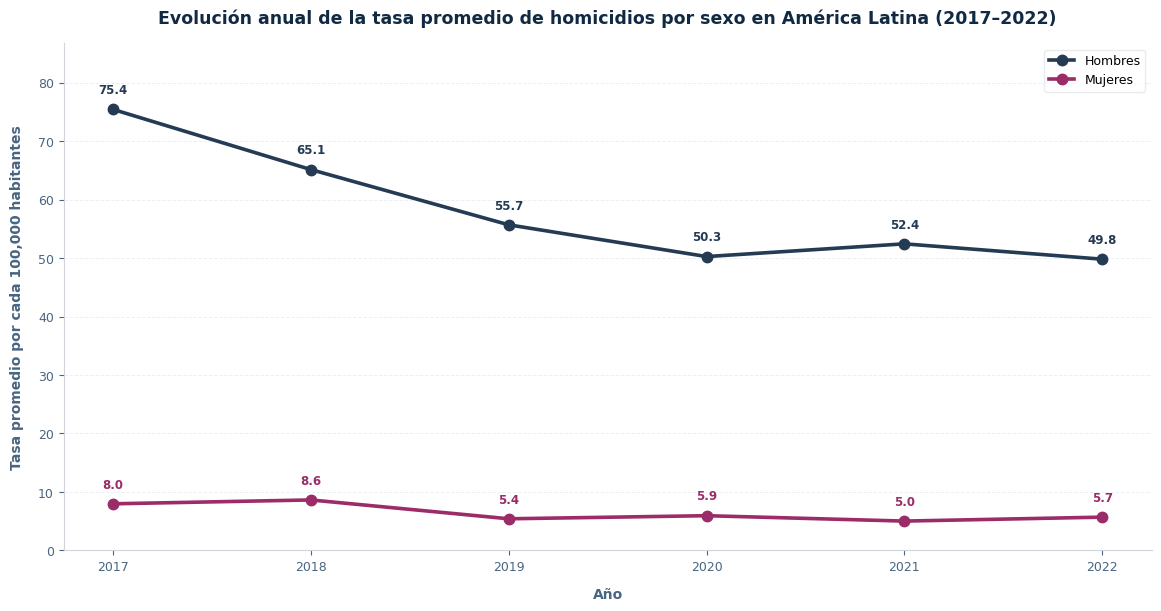

In [ ]:
# Definir la lista 'a' con los 10 países con mayores tasas medianas
a = lfh.groupby("country")["homicide_rate"].median().nlargest(10).index

comparacion_sexo = (
    lfh[lfh["country"].isin(a)]
    .groupby("year")[["male_homicide_rate", "female_homicide_rate"]]
    .mean()
)

fig, ax = plt.subplots(figsize=(11.5, 6), constrained_layout=True)

ax.plot(
    comparacion_sexo.index, comparacion_sexo["male_homicide_rate"],
    marker="o", markersize=7.5, linewidth=2.6,
    color=PALETA_ESTUDIO['neutro_oscuro'], label="Hombres"
)
ax.plot(
    comparacion_sexo.index, comparacion_sexo["female_homicide_rate"],
    marker="o", markersize=7.5, linewidth=2.6,
    color=PALETA_ESTUDIO['acento_mujer'], label="Mujeres"
)

for year, row in comparacion_sexo.iterrows():
    ax.text(year, row["male_homicide_rate"] + 2.2, f"{row['male_homicide_rate']:.1f}",
            ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=PALETA_ESTUDIO['neutro_oscuro'])
    ax.text(year, row["female_homicide_rate"] + 2.2, f"{row['female_homicide_rate']:.1f}",
            ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=PALETA_ESTUDIO['acento_mujer'])

ax.set_title("Evolución anual de la tasa promedio de homicidios por sexo en América Latina (2017–2022)", pad=14)
ax.set_xlabel("Año", labelpad=10)
ax.set_ylabel("Tasa promedio por cada 100,000 habitantes", labelpad=10)
ax.set_xticks(comparacion_sexo.index)
ax.set_ylim(0, comparacion_sexo["male_homicide_rate"].max() * 1.15)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.8)
ax.grid(axis='x', visible=False)
sns.despine(ax=ax)

plt.show()

**Interpretación:** Entre 2017 y 2022, las tasas promedio de homicidio masculino muestran una tendencia general a la baja. En 2017 se registra el valor más alto, con 75.4 homicidios por cada 100,000 habitantes. A partir de ese año, la tasa disminuye de manera continua hasta llegar a 50.3 en 2020. Aunque en 2021 se observa un ligero incremento a 52.4, en 2022 vuelve a descender, alcanzando 49.8. En conjunto, esto representa una reducción importante respecto al inicio del periodo.

Por otro lado, las tasas promedio de homicidio femenino se mantienen considerablemente por debajo de las masculinas. En 2017 y 2018 registran valores de 8.0 y 8.6, respectivamente; posteriormente disminuyen y presentan pequeñas fluctuaciones, hasta ubicarse en 5.7 homicidios por cada 100,000 habitantes en 2022.

La diferencia entre ambos sexos se mantiene durante los seis años analizados, aunque las tasas masculinas presentan cambios mucho más pronunciados. En general, los resultados muestran que la disminución de la tasa promedio de homicidios se observa principalmente en los hombres, mientras que en las mujeres también existe una reducción, pero de menor magnitud y con variaciones más moderadas.

### **4.7 Relación entre la tenencia civil de armas y los homicidios con arma de fuego**

**Diagrama de dispersión: tenencia civil de armas y tasa de homicidios con arma de fuego:** muestra la relación entre el número de armas de fuego civiles por cada 100 habitantes en 2017 y la tasa promedio de homicidios con arma de fuego por cada 100,000 habitantes. La comparación tiene un alcance global e incluye países de distintas regiones y niveles de ingreso, lo que permite observar el comportamiento de América Latina y el Caribe en relación con el resto del mundo. Los países se distinguen por nivel de ingreso y se utiliza una escala logarítmica en el eje vertical para facilitar la visualización de las diferencias entre países con tasas muy distintas.

- **¿Qué información podemos obtener?** Nos permite explorar si una mayor tenencia civil de armas se relaciona con tasas más elevadas de homicidios con arma de fuego, identificar países que presentan comportamientos particulares y comparar la situación de América Latina con la de otras regiones del mundo, considerando también las diferencias entre niveles de ingreso.

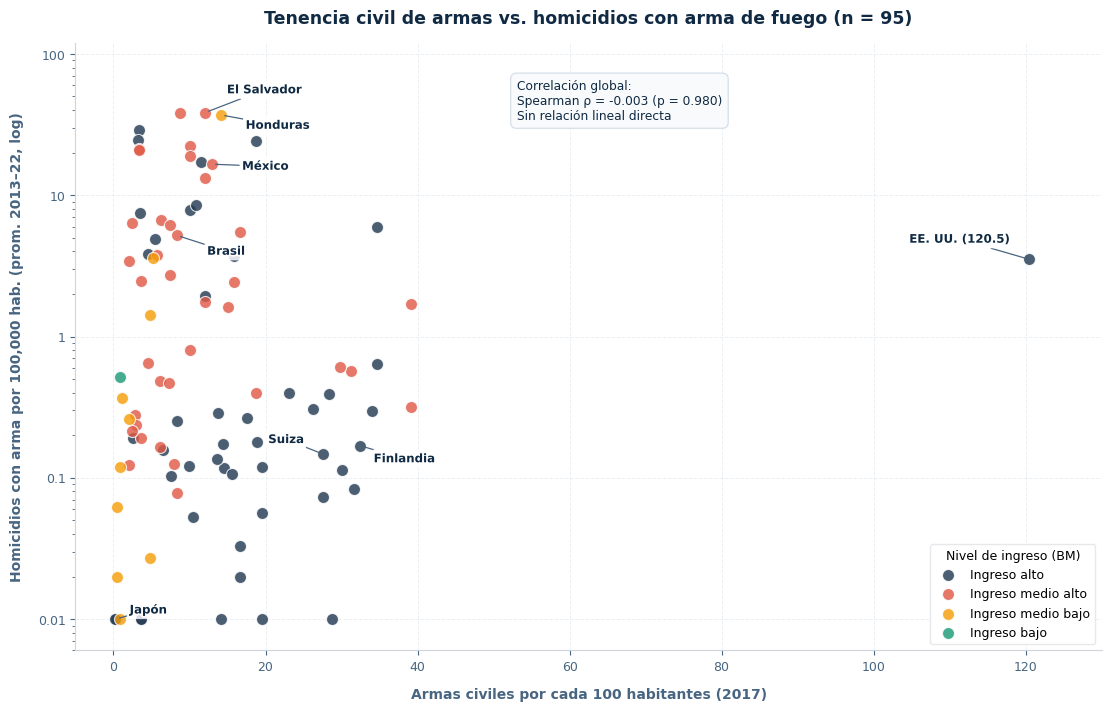

In [ ]:
import matplotlib.patheffects as path_effects

fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)

sub_3a = cgp_limpio.dropna(
    subset=['firearms_per_100_people', 'avg_2013_2022_firearm_homicide_rate', 'income_group']
).copy()

sub_3a['hom_plot'] = sub_3a['avg_2013_2022_firearm_homicide_rate'].clip(lower=0.01)

inc_palette = {
    'High income': PALETA_ESTUDIO['neutro_oscuro'],
    'Upper middle income': PALETA_ESTUDIO['primario'],
    'Lower middle income': '#F59E0B',
    'Low income': PALETA_ESTUDIO['secundario']
}

inc_es = {
    'High income': 'Ingreso alto',
    'Upper middle income': 'Ingreso medio alto',
    'Lower middle income': 'Ingreso medio bajo',
    'Low income': 'Ingreso bajo'
}

for inc in ['High income', 'Upper middle income', 'Lower middle income', 'Low income']:
    d = sub_3a[sub_3a['income_group'] == inc]
    ax.scatter(
        d['firearms_per_100_people'],
        d['hom_plot'],
        label=inc_es[inc],
        color=inc_palette[inc],
        s=75,
        alpha=0.82,
        edgecolors='white',
        linewidth=0.8,
        zorder=3
    )

ax.set_yscale('log')
ax.set_ylim(0.006, 120)
ax.set_xlim(-5, 130)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:g}"))

ax.set_xlabel('Armas civiles por cada 100 habitantes (2017)', labelpad=10)
ax.set_ylabel('Homicidios con arma por 100,000 hab. (prom. 2013–22, log)', labelpad=10)
ax.set_title('Tenencia civil de armas vs. homicidios con arma de fuego (n = 95)', pad=14)

# Coordenadas ajustadas (Suiza hacia la izquierda)
notas_3a = {
    'USA': ('EE. UU. (120.5)', (-14, 12)),
    'SLV': ('El Salvador', (16, 14)),
    'HND': ('Honduras', (18, -10)),
    'MEX': ('México', (22, -4)),
    'BRA': ('Brasil', (22, -14)),
    'CHE': ('Suiza', (-14, 8)),            # Desplazado hacia la izquierda
    'FIN': ('Finlandia', (10, -12)),
    'JPN': ('Japón', (10, 4))
}

for iso, (txt, off) in notas_3a.items():
    r = sub_3a[sub_3a['iso3'] == iso]
    if not r.empty:
        ann = ax.annotate(
            txt,
            (r.iloc[0]['firearms_per_100_people'], r.iloc[0]['hom_plot']),
            xytext=off,
            textcoords='offset points',
            ha='right' if off[0] < 0 else 'left',
            fontsize=8.5,
            fontweight='bold',
            color=PALETA_ESTUDIO['texto'],
            zorder=5,
            bbox=dict(
                boxstyle='round,pad=0.22',
                facecolor='white',
                edgecolor='none',
                alpha=0.82
            ),
            arrowprops=dict(
                arrowstyle='-',
                color=PALETA_ESTUDIO['subtexto'],
                lw=0.9,
                shrinkA=0,
                shrinkB=3
            )
        )
        ann.set_path_effects([
            path_effects.Stroke(linewidth=2.5, foreground='white'),
            path_effects.Normal()
        ])

ax.text(
    0.43, 0.94,
    "Correlación global:\nSpearman ρ = -0.003 (p = 0.980)\nSin relación lineal directa",
    transform=ax.transAxes,
    fontsize=8.8,
    color=PALETA_ESTUDIO['texto'],
    va='top',
    zorder=5,
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='#F8FAFC',
        edgecolor='#D9E2EC',
        linewidth=1
    )
)

ax.legend(
    loc='lower right',
    title='Nivel de ingreso (BM)',
    title_fontsize=9,
    framealpha=0.95
)

ax.grid(True, alpha=0.8, zorder=0)
sns.despine(ax=ax)
plt.show()

**Interpretación:** En la gráfica no se observa una relación clara entre la cantidad de armas civiles por cada 100 habitantes y la tasa de homicidios con arma de fuego. Esto coincide con el resultado de Spearman (\(\rho=-0.003\), \(p=0.980\)), que indica que no existe una asociación estadísticamente significativa entre ambas variables en los 95 países analizados.

Algunos países permiten ver mejor estas diferencias. Estados Unidos destaca por tener la mayor cantidad de armas civiles, con 120.5 por cada 100 habitantes, pero su tasa de homicidios con arma de fuego es de aproximadamente 3.5. En cambio, Honduras, El Salvador, México y Brasil presentan tasas mucho más elevadas, aunque su tenencia civil de armas es considerablemente menor. Suiza y Finlandia también llaman la atención porque, a pesar de tener una cantidad importante de armas, registran tasas bajas de homicidios con arma de fuego.

Por nivel de ingreso, varios países de ingreso medio alto (rojo) se ubican en los niveles más elevados de homicidios con arma de fuego. En cambio, los países de ingreso alto (azul) muestran tasas más variadas, incluso cuando algunos tienen una tenencia de armas considerable. Esto refleja que las diferencias entre países no siguen un patrón definido a partir de la cantidad de armas civiles.

Con estos resultados no se puede afirmar que los países con más armas civiles tengan mayores tasas de homicidios con arma de fuego. La relación entre ambas variables es prácticamente nula en la muestra, por lo que la tenencia civil de armas, por sí sola, no permite explicar las diferencias observadas entre países. Para entender mejor este comportamiento sería necesario considerar otros factores y contar con información adicional.

### **4.8 Análisis de los 10 países de América Latina con mayores tasas de homicidio (2017–2022)**

En este apartado se seleccionan los 10 países de América Latina con las tasas de homicidio más elevadas durante el periodo de estudio. Esta selección permite centrar el análisis en los países donde la violencia homicida representa un problema de mayor magnitud en términos de incidencia, en lugar de considerar únicamente el comportamiento promedio de toda la región. Además, estudiar este grupo permite profundizar en las diferencias que existen entre los países con mayores niveles de violencia, identificar si mantienen tasas persistentemente elevadas o presentan variaciones importantes a lo largo del tiempo y explorar qué características podrían estar relacionadas con este comportamiento.

El análisis del Top 10 también permite examinar si los países con mayores tasas de homicidio comparten determinadas condiciones socioeconómicas o si, a pesar de presentar niveles similares de violencia, tienen contextos económicos y demográficos diferentes. Esto resulta relevante para evitar asumir que la violencia homicida responde a una sola condición y para explorar la diversidad de factores asociados con su comportamiento en América Latina.


In [ ]:
top_10 = (
    lfh.groupby("country")["homicide_rate"]
    .median()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_10.columns = ["País", "Tasa mediana de homicidios"]

top_10.style.format({
    "Tasa mediana de homicidios": "{:.2f}"
}).hide(axis="index").set_caption("Top 10 países con mayores tasas medianas de homicidio")

País,Tasa mediana de homicidios
Jamaica,49.70
Turks and Caicos Islands,41.38
Honduras,38.09
Trinidad and Tobago,34.70
Belize,33.17
St. Vincent and the Grenadines,32.14
El Salvador,30.02
"Venezuela, RB",29.48
Mexico,28.48
St. Lucia,28.48


Este Top 10 corresponde a los países de América Latina y el Caribe que registraron las mayores tasas medianas de homicidio entre 2017 y 2022. Jamaica ocupa el primer lugar, con una mediana de 49.70 homicidios por cada 100,000 habitantes, seguida de Islas Turcas y Caicos (41.38) y Honduras (38.09). Destaca que varios de los países seleccionados pertenecen al Caribe y Centroamérica, regiones donde la violencia se ha relacionado con disputas entre pandillas, tráfico de drogas y presencia de grupos criminales.

En Jamaica y Trinidad y Tobago, los conflictos entre pandillas han sido un problema importante. Honduras y Belice también han enfrentado problemas de violencia vinculados con el crimen organizado y el tráfico de drogas. El Salvador destaca por haber registrado tasas muy elevadas durante algunos años del periodo, aunque posteriormente presentó una reducción importante.

México y Venezuela también forman parte del ranking, en contextos donde existen disputas entre organizaciones criminales y problemas de seguridad. Sin embargo, los países seleccionados no necesariamente comparten las mismas causas de violencia, por lo que resulta importante analizar sus diferencias y explorar qué otras variables podrían estar relacionadas con sus tasas de homicidio.

### **4.8.1 Distribución de las tasas de homicidio por país**

**Diagramas de caja: distribución de las tasas de homicidio en los 10 países de América Latina seleccionados (2017–2022):** muestra la distribución de las tasas de homicidio de cada país mediante diagramas de caja, ordenados de mayor a menor según su mediana. Esta visualización permite comparar no solo el nivel central de las tasas, sino también su dispersión, variabilidad y posibles valores atípicos durante el periodo de estudio.

- **¿Qué información podemos obtener?** Nos permite identificar qué países presentan las tasas medianas de homicidio más elevadas, cuáles muestran mayor variabilidad a lo largo del periodo y en cuáles las tasas se mantienen relativamente estables. También permite detectar observaciones atípicas que reflejan años con niveles de violencia particularmente altos o bajos. De esta manera, podemos comparar las diferencias en el comportamiento de la violencia homicida entre los países seleccionados.

/tmp/ipykernel_1140/3822096216.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


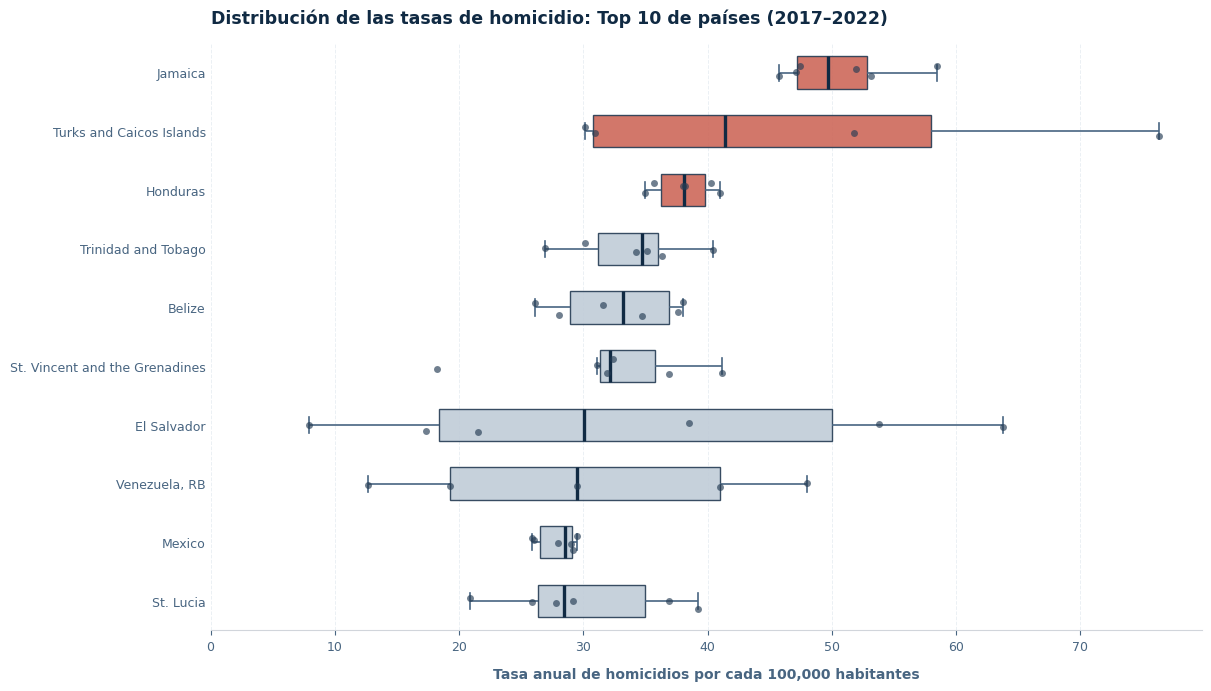

In [ ]:
orden = (
    lfh.groupby("country")["homicide_rate"]
    .median()
    .sort_values(ascending=False)
    .head(10)
    .index
)

datos = lfh[lfh["country"].isin(orden)].copy()

fig, ax = plt.subplots(figsize=(12, 6.8), constrained_layout=True)

# Resaltar el Top 3 en coral intenso y el resto en azul niebla
paleta_top10 = [
    PALETA_ESTUDIO['primario'] if i < 3 else PALETA_ESTUDIO['neutro_claro']
    for i in range(len(orden))
]

sns.boxplot(
    data=datos,
    x="homicide_rate",
    y="country",
    order=orden,
    orient="h",
    width=0.55,
    palette=paleta_top10,
    showfliers=False,
    medianprops=dict(color=PALETA_ESTUDIO['texto'], linewidth=2.4),
    whiskerprops=dict(color=PALETA_ESTUDIO['subtexto'], linewidth=1.2),
    capprops=dict(color=PALETA_ESTUDIO['subtexto'], linewidth=1.2),
    boxprops=dict(edgecolor=PALETA_ESTUDIO['neutro_oscuro'], linewidth=1, alpha=0.9),
    ax=ax
)

# Puntos individuales bien contrastados
sns.stripplot(
    data=datos,
    x="homicide_rate",
    y="country",
    order=orden,
    color=PALETA_ESTUDIO['neutro_oscuro'],
    size=5,
    alpha=0.65,
    jitter=0.14,
    ax=ax
)

ax.set_title(
    "Distribución de las tasas de homicidio: Top 10 de países (2017–2022)",
    loc="left",
    pad=14
)

ax.set_xlabel("Tasa anual de homicidios por cada 100,000 habitantes", labelpad=10)
ax.set_ylabel("")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.8)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
sns.despine(ax=ax, left=True)

plt.show()

**Interpretación:** De este boxplot podemos ver el top 10 no tiene un comportamiento uniforme. Jamaica, Honduras, Trinidad y Tobago, Belice, México y San Vicente y las Granadinas presentan tasas elevadas con una variabilidad relativamente menor, lo que indica que sus niveles de violencia se mantuvieron altos durante buena parte del periodo. Por otro lado, El Salvador, Venezuela e Islas Turcas y Caicos muestran variaciones mucho más amplias. Esto significa que su posición entre los países con mayores tasas medianas también está relacionada con los cambios que experimentaron de un año a otro.

### **4.8.2 Relación entre variables socioeconómicas y la tasa de homicidio en los 10 países seleccionados de América Latina (2017–2022)**

**Diagramas de dispersión: variables socioeconómicas y tasa de homicidio:** se presentan tres diagramas de dispersión que muestran la relación entre la tasa de homicidio y tres variables socioeconómicas: porcentaje de desempleo, PIB per cápita y porcentaje de población urbana. El análisis considera los 10 países seleccionados de América Latina durante el periodo 2017–2022. En cada gráfico se incorpora una línea de tendencia lineal y se calculan las correlaciones de Pearson y Spearman para explorar la dirección y la intensidad de las asociaciones entre las variables.

- **¿Qué información podemos obtener?** Nos permite explorar si existe una relación entre las condiciones socioeconómicas y las tasas de homicidio, identificar patrones o tendencias y comparar qué variables presentan asociaciones más fuertes con la violencia homicida. También permite reconocer posibles diferencias entre los países y la variabilidad de los datos a lo largo del periodo analizado.

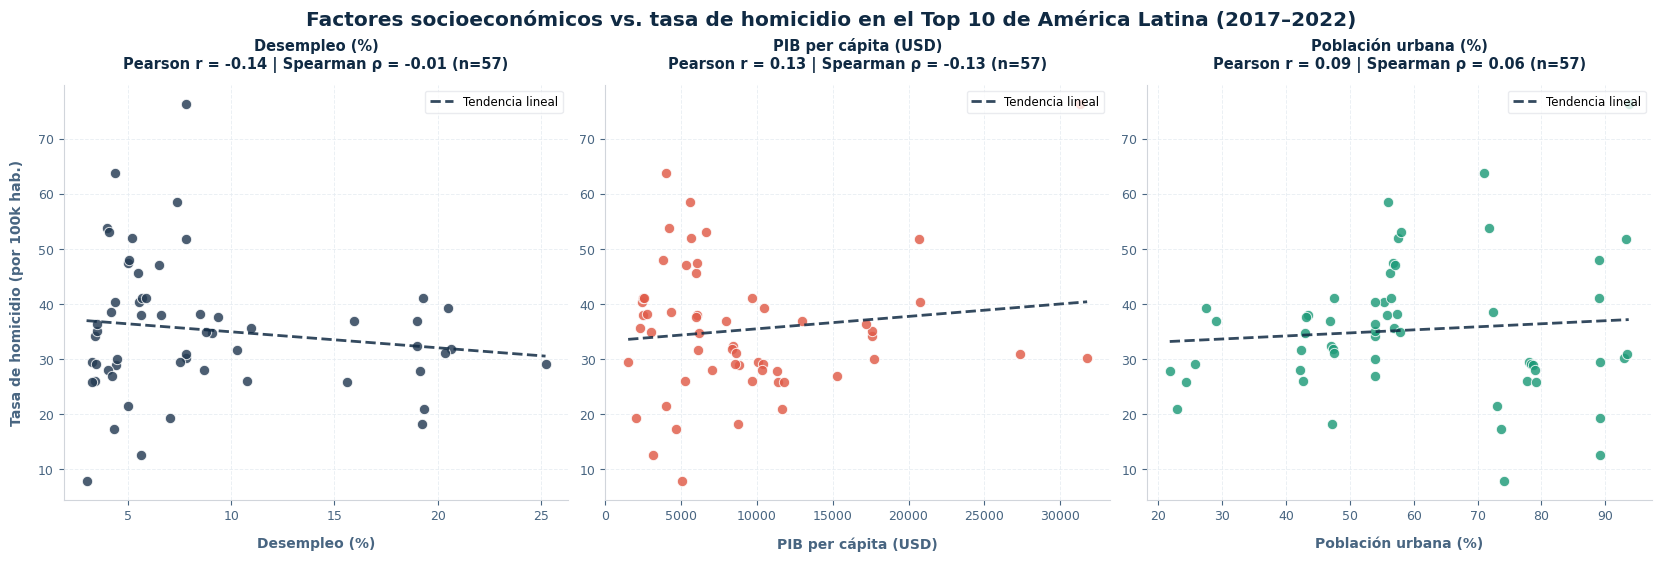

In [ ]:
paises_top10 = lfh.groupby("country")["homicide_rate"].median().nlargest(10).index
df_top10 = lfh[lfh["country"].isin(paises_top10)]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.5), constrained_layout=True)

pares = [
    ("unemployment_pct", "Desempleo (%)", PALETA_ESTUDIO['neutro_oscuro']),
    ("gdp_per_capita_usd", "PIB per cápita (USD)", PALETA_ESTUDIO['primario']),
    ("urban_population_pct", "Población urbana (%)", PALETA_ESTUDIO['secundario']),
]

for ax, (xvar, xlabel, col) in zip(axes.flat, pares):
    df_sc = df_top10[["country", "year", "homicide_rate", xvar]].dropna()

    ax.scatter(
        df_sc[xvar],
        df_sc["homicide_rate"],
        alpha=0.82,
        s=55,
        color=col,
        edgecolors="white",
        linewidths=0.7,
        zorder=3
    )

    if len(df_sc) > 5:
        z = np.polyfit(df_sc[xvar], df_sc["homicide_rate"], 1)
        x_rng = np.linspace(df_sc[xvar].min(), df_sc[xvar].max(), 100)
        ax.plot(
            x_rng,
            np.poly1d(z)(x_rng),
            color=PALETA_ESTUDIO['texto'],
            linewidth=2,
            linestyle="--",
            alpha=0.85,
            label="Tendencia lineal",
            zorder=4
        )

    r_p = df_sc[xvar].corr(df_sc["homicide_rate"])
    r_s = df_sc[xvar].corr(df_sc["homicide_rate"], method="spearman")

    ax.set_title(
        f"{xlabel}\nPearson r = {r_p:.2f} | Spearman ρ = {r_s:.2f} (n={len(df_sc)})",
        fontsize=10.5,
        pad=12
    )
    ax.set_xlabel(xlabel, labelpad=10)
    ax.set_ylabel("Tasa de homicidio (por 100k hab.)" if ax == axes[0] else "", labelpad=10)
    ax.grid(True, alpha=0.8, zorder=0)
    ax.legend(loc="upper right", fontsize=8.5)
    sns.despine(ax=ax)

fig.suptitle(
    "Factores socioeconómicos vs. tasa de homicidio en el Top 10 de América Latina (2017–2022)",
    fontsize=14.5,
    fontweight="bold",
    color=PALETA_ESTUDIO['texto']
)

plt.show()

**Interpretación:** Se analizó la relación entre la tasa de homicidio y tres variables socioeconómicas: el porcentaje de desempleo, el PIB per cápita y el porcentaje de población urbana. En los tres casos se observan correlaciones débiles, con valores de Pearson de -0.14, 0.13 y 0.09, respectivamente. Los coeficientes de Spearman también se mantienen cercanos a cero (-0.01, -0.13 y 0.06), por lo que no se identifica una asociación monotónica clara entre las variables. Esto coincide con la dispersión de los puntos y las pendientes poco pronunciadas de las líneas de tendencia. Aunque se observan algunos países con tasas de homicidio elevadas en distintos niveles de desempleo, ingreso y urbanización, no parece existir un comportamiento común que permita relacionar directamente estos factores con la violencia dentro del grupo analizado. Es importante considerar que el análisis se limita a los 10 países con mayores tasas medianas de homicidio entre 2017 y 2022, por lo que los resultados no necesariamente representan el comportamiento de toda América Latina y el Caribe.

### **4.8.3 Análisis de correlaciones entre la tasa de homicidio y las variables socioeconómicas por país**

**Mapa de calor de correlaciones entre la tasa de homicidio y otras variables por país:** muestra la correlación entre `homicide_rate` y las distintas variables disponibles para cada uno de los 10 países seleccionados. Los resultados se representan mediante un mapa de calor, donde los colores y valores permiten identificar la dirección y la intensidad de las asociaciones entre las variables.

- **¿Qué información podemos obtener?** Nos permite identificar qué variables presentan asociaciones positivas o negativas con la tasa de homicidio en cada país, comparar si estas relaciones son similares o diferentes entre los países del Top 10 y reconocer posibles patrones particulares. Esto ayuda a profundizar en el análisis de los factores relacionados con la violencia homicida, sin asumir que las correlaciones representan relaciones de causalidad.

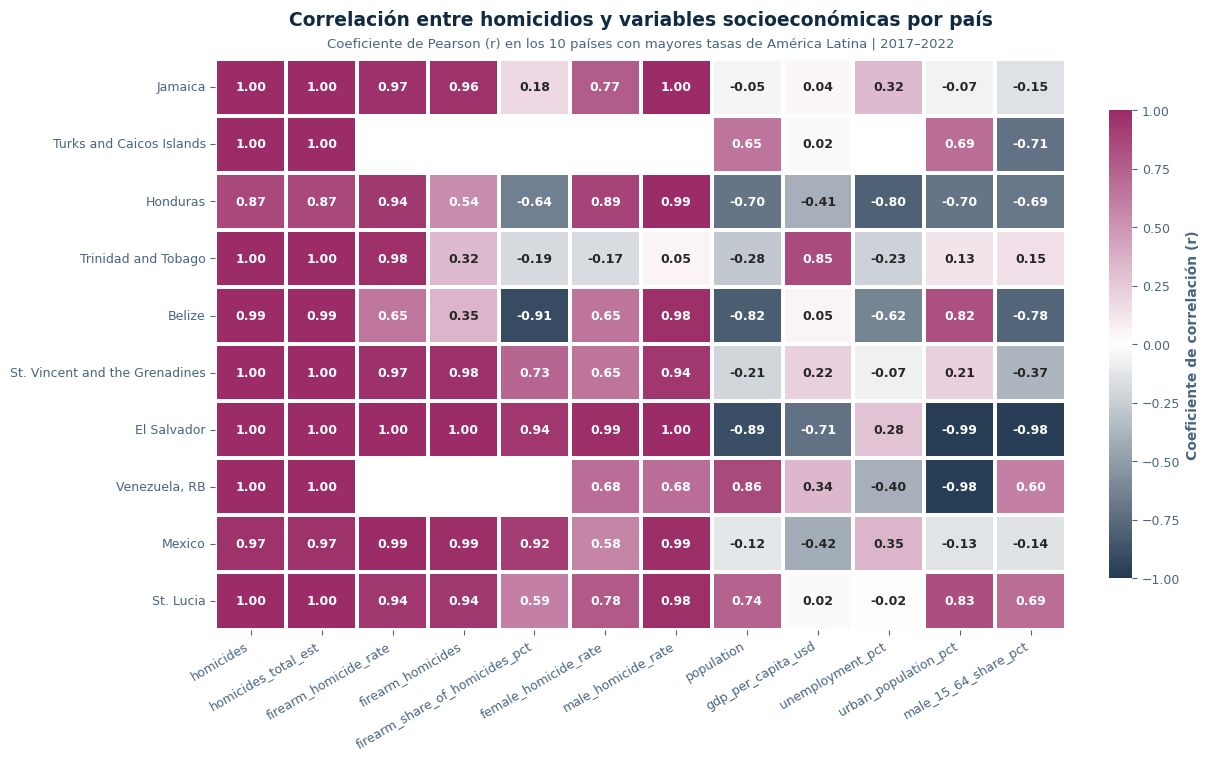

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

paises_top10 = lfh.groupby("country")["homicide_rate"].median().nlargest(10).index

corr_homicide = (
    lfh[lfh["country"].isin(paises_top10)]
    .drop(columns=["iso3", "region", "income_group", "year"], errors="ignore")
    .groupby("country")
    .corr(numeric_only=True)
    .xs("homicide_rate", level=1)
    .drop(columns="homicide_rate")
    .reindex(paises_top10)
)

# Mapa de color divergente: Azul Índigo (-) -> Blanco (0) -> Ciruela (+)
cmap_editorial = LinearSegmentedColormap.from_list(
    "editorial_genero",
    [PALETA_ESTUDIO['neutro_oscuro'], "#FFFFFF", PALETA_ESTUDIO['acento_mujer']],
    N=256
)

fig, ax = plt.subplots(figsize=(12, 7.5), constrained_layout=True)

sns.heatmap(
    corr_homicide,
    cmap=cmap_editorial,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 9, "weight": "semibold"},
    linewidths=1.5,
    linecolor="white",
    cbar_kws={"shrink": 0.82, "label": "Coeficiente de correlación (r)"},
    ax=ax
)

# Título principal y subtítulo
ax.set_title(
    "Correlación entre homicidios y variables socioeconómicas por país",
    fontsize=13.5,
    fontweight="bold",
    color=PALETA_ESTUDIO['texto'],
    pad=24
)

ax.text(
    0.5, 1.02,
    "Coeficiente de Pearson (r) en los 10 países con mayores tasas de América Latina | 2017–2022",
    transform=ax.transAxes,
    ha="center",
    fontsize=9.5,
    color=PALETA_ESTUDIO['subtexto']
)

ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.show()

**Interpretación:** El mapa de calor muestra que las correlaciones entre la tasa de homicidio y las demás variables cambian considerablemente de un país a otro. Por ejemplo, la relación entre el año y la tasa de homicidio es fuertemente negativa en El Salvador y Venezuela, lo que coincide con las reducciones observadas durante el periodo. En cambio, en países como Santa Lucía e Islas Turcas y Caicos, esta relación es positiva. Respecto al PIB per cápita y el desempleo, las asociaciones presentan resultados distintos entre países, sin mostrar una tendencia común que permita relacionar estas variables de manera consistente con las tasas de homicidio. Esto coincide con los resultados del análisis socioeconómico, en el que tampoco se identificaron asociaciones claras para el conjunto de países seleccionados. También aparecen correlaciones elevadas con variables que miden aspectos estrechamente relacionados con la tasa de homicidio, por lo que deben interpretarse con precaución. Finalmente, es importante considerar que estos resultados son exploratorios, ya que se cuenta únicamente con seis observaciones anuales por país, lo que hace que las correlaciones puedan ser sensibles a los cambios de un solo año. En conjunto, los resultados refuerzan la idea de que las diferencias en la violencia homicida no pueden explicarse mediante un único factor socioeconómico y que las relaciones observadas varían según el contexto de cada país.

## **5. Interpretación y conclusiones**
Presenten sus principales hallazgos y expliquen cómo se relacionan con las preguntas planteadas
inicialmente.

Distingan claramente entre lo que los datos permiten concluir y aquello que no puede afirmarse con la información disponible.

Recuerden que una correlación no implica causalidad y que un análisis exploratorio no constituye, por
sí mismo, una demostración de relaciones causales.

<p align="justify">El análisis exploratorio y estadístico realizado sobre los conjuntos de datos de tenencia civil de armas (civilian_firearms_2017.csv), perfiles nacionales (country_gun_profile.csv) y series longitudinales de violencia homicida (firearm_homicides_country_year.csv) permite responder de manera fundamentada a las preguntas planteadas y realizar hallazgos importantes de América Latina y el Caribe, que es nuestra región de interés.</p>

<p align="justify">Debido a la alta proporción de registros faltantes en años anteriores, particularmente entre 2000 y 2004, donde la cobertura global de homicidios con arma de fuego es nula, se delimitó el análisis al periodo 2017–2022, ventana que además coincide con el corte de tenencia civil de armas de 2017. Para el tratamiento de datos faltantes se estableció un umbral máximo del 20%: las variables que superaron este límite fueron descartadas del análisis multivariado para evitar fabricar información artificial y distorsionar las correlaciones. En las variables con 20% o menos de datos faltantes, la inspección de sus histogramas confirmó distribuciones fuertemente asimétricas, por lo que cualquier imputación debe basarse en medidas robustas como la mediana y nunca en la media aritmética.
</p>

<h2>Respuesta a la Pregunta 1 ¿Qué características comparten los países de América Latina y el Caribe que presentan las mayores tasas de homicidio?

<p align="justify">América Latina y el Caribe registra la mayor incidencia de homicidios entre las regiones analizadas, con una tasa media de 20.95 homicidios por cada 100,000 habitantes, de los cuales 14.66 corresponden a homicidios con armas de fuego. Sin embargo, no se identifica un perfil socioeconómico homogéneo entre los países más violentos. Variables como el PIB per cápita, el desempleo, la matriculación secundaria y la tenencia civil de armas no muestran un patrón consistente que permita explicar las diferencias observadas.</p>

<p align="justify">Esta dificultad se relaciona también con la falta de información en variables relevantes, como la desigualdad económica (gini_index) y el origen ilícito de las armas incautadas (seized_arms_illicit_origin_pct), que fueron excluidas por su baja cobertura. Asimismo, la ausencia de registros sobre tenencia civil de armas en países como Venezuela limita el análisis de la relación entre disponibilidad de armas y violencia.</p>

<p align="justify">A pesar de estas limitaciones, se identifican algunas características comunes, como una marcada concentración de víctimas masculinas, con una tasa media de 38.37 homicidios por cada 100,000 habitantes, frente a 4.55 en mujeres; una elevada incidencia de homicidios cometidos con armas de fuego, sin una relación directa aparente con la tenencia civil legal registrada; y una concentración predominante de estos países en los grupos de ingreso medio.</p>

<p align="justify">Por último, aunque los niveles de violencia se mantuvieron relativamente elevados durante el periodo 2017-2022, su evolución fue heterogénea: algunos países redujeron considerablemente sus tasas de homicidio, mientras que otros experimentaron incrementos. Esto sugiere la influencia de condiciones particulares de cada nación, como los contextos económicos, políticos y de seguridad pública.</p>

<h2>Para la pregunta 2: ¿Existe una asociación entre la tenencia civil de armas de fuego y las tasas de homicidio con armas de fuego a nivel internacional?</h2>

<p align="justify">No existe una asociación lineal positiva entre la tenencia civil de armas y las tasas de homicidio con armas de fuego a nivel internacional
</p>

<p align="justify">Los datos indican que no existe una asociación lineal positiva entre la tenencia civil de armas y los homicidios con arma de fuego a nivel internacional. De hecho, el coeficiente de correlación de Pearson entre la tasa de armas civiles y la tasa promedio de homicidios con arma de fuego (2017–2022) es prácticamente nulo.</p>

<p align="justify">Al agrupar los países según su nivel de ingreso (income_group), se observa que las naciones de ingreso alto concentran la mayor tenencia civil promedio con 14.26 armas por cada 100 habitantes, pero mantienen una tasa moderada-baja de homicidios con arma de fuego de 3.08. Por el contrario, los países de ingreso medio-alto presentan una menor tenencia promedio (9.25 armas por cada 100 habitantes), pero registran la tasa promedio más alta de homicidios con arma de fuego, alcanzando 6.63.</p>


<h2>Respuesta a la Pregunta 3 ¿Qué regiones presentan una mayor proporción de homicidios cometidos con armas de fuego?</h2>

<p align="justify">
Durante el periodo 2017–2022, América Latina y el Caribe registró los niveles más elevados de violencia homicida entre las regiones analizadas. La región presentó una tasa media de homicidio de 20.95 por cada 100,000 habitantes y una mediana de 16.09, valores considerablemente superiores a los observados en el resto del mundo. En comparación, África Subsahariana registró una media de 9.42 homicidios por cada 100,000 habitantes, mientras que América del Norte alcanzó 4.66 y Europa y Asia Central apenas 2.61.
</p>
<p align="justify">
Adicionalmente, una proporción importante de los homicidios registrados en América Latina y el Caribe se realizo mediante armas de fuego, su tasa media de homicidio con estas alcanzó 14.66 por cada 100,000 habitantes, lo que representa aproximadamente el 70% de la tasa total de homicidios de la región. Estos resultados sugieren que las armas de fuego constituyen uno de los principales mecanismos asociados a los homicidios en América Latina.
</p>

<p align="justify">
La diferencia entre la media y la mediana nos indican la presencia de países con niveles muy altos de violencia que incrementan el promedio de la región, y aun con la mediana considerada, América Latina y el Caribe continúa registrando tasas de homicidio muy superiores a las del resto de las regiones, mostrando que la tasa de homicidio es muy alta en la región y no únicamente es el resultado de algunos paises con casos extremos.
</p>

<p align="justify">
En conclusión, América Latina y el Caribe concentra tanto las mayores tasas de homicidio como una de las mayores proporciones de homicidios cometidos con armas de fuego durante el periodo estudiado.
</p>

<h2>Respuesta a la Pregunta 4 ¿Cómo se relacionan las condiciones socioeconómicas, como el ingreso, el desempleo y la desigualdad, con los niveles de violencia homicida?</h2>

<p align="justify">
Como mencionado anteriormente, el análisis muestra que variables como el desempleo, el PIB per cápita (gdp) y la urbanización presentan asociaciones inconsistentes con las tasas de homicidio observadas en América Latina y el Caribe, ya que, aunque algunos de los países con mayores niveles de violencia presentan condiciones económicas desfavorables, este patrón no se mantiene de forma uniforme en toda la región, hagase los ejemplos de El Salvador, Honduras y México.
</p>

<p align="justify">
Adicionalmente, países con niveles similares de ingreso, desempleo o urbanización pueden presentar trayectorias muy distintas de homicidios por cientos de miles de personas, sugiriendo que las variables socioeconómicas ayudan a contextualizar el fenómeno, pero no son suficientes para explicar por sí solas las diferencias observadas entre países para latinoamérica.
</p>

<p align="justify">
En consecuencia, los resultados indican que la violencia homicida responde a una combinación de factores económicos, sociales y gubernamentales. Elementos como las políticas de seguridad pública, la presencia de organizaciones criminales, la capacidad estatal, la corrupción o las características únicas de cada país podrían desempeñar un papel importante, aunque no se encuentran completamente representados para un periodo mas largo y completo en la historia de latinoamérica.
</p>


<h3>Entonces...</h3>

<p>¿Las variables socioeconómicas son suficientes para explicar la violencia?</p>

<p align="justify">
Los análisis exploratorios realizados sugieren que variables como desempleo, urbanización o PIB per cápita presentan asociaciones limitadas o inconsistentes con las tasas de homicidio. La ausencia de relaciones claras indica que el fenómeno probablemente depende de factores adicionales no incluidos en la base de datos, como calidad institucional, corrupción, presencia de grupos criminales organizados, efectividad policial o políticas de seguridad pública.<p>

<p>¿Qué nos dicen las diferencias entre hombres y mujeres?</p>

<p align="justify">
La tasa de homicidios masculinos supera ampliamente a la femenina en prácticamente todos los países analizados. Esto indica que la violencia letal afecta de forma desproporcionada a los hombres, posiblemente debido a una mayor exposición a contextos de criminalidad, conflictos interpersonales y actividades relacionadas con organizaciones delictivas.</p>

<h2>En conclusión</h2>

<p align="justify">
En conjunto, los resultados obtenidos muestran que América Latina y el Caribe continúa siendo la región con los niveles más elevados de violencia homicida dentro de la muestra analizada durante el periodo 2017–2022. La región no solo registra las tasas de homicidio más altas a nivel internacional, sino también una elevada participación de armas de fuego en los eventos letales, lo que evidencia el papel central de este mecanismo en la violencia regional.
</p>

<p align="justify">
Sin embargo, el análisis realizado no encontró evidencia de una relación lineal directa entre la tenencia civil de armas y las tasas de homicidio con arma de fuego a nivel internacional. Asimismo, las variables socioeconómicas consideradas, como el PIB per cápita, el desempleo y la urbanización, mostraron asociaciones limitadas o inconsistentes, sugiriendo que la violencia homicida no puede explicarse adecuadamente mediante un único conjunto de factores.
</p>

<p align="justify">
La importante heterogeneidad observada entre países, incluso dentro de una misma región, indica que factores institucionales, políticos y relacionados con la seguridad pública podrían desempeñar un papel igualmente relevante. En consecuencia, los resultados deben interpretarse como evidencia exploratoria y descriptiva, más que como una demostración de relaciones causales.
</p>

<p align="justify">
Finalmente, este estudio pone de manifiesto la necesidad de incorporar información adicional sobre crimen organizado, capacidad institucional, corrupción, políticas de seguridad y contextos históricos nacionales para comprender con mayor profundidad las causas de la violencia homicida. La complejidad del fenómeno sugiere que su explicación requiere una perspectiva multidimensional que trascienda las variables disponibles en la base de datos analizada.
</p>